# Phase 2.8 — Exploratory Data Analysis (Phase 3 go/no-go)

Narrative companion to `eda/run_eda.py`. **This notebook computes nothing**: it reads the official outputs in
`outputs/eda/` (figures, `eda_metrics.json`), so what it shows is exactly what the gate was decided on.

1. `python eda/run_eda.py` (official run; writes `outputs/eda/`)
2. `jupyter nbconvert --execute --to notebook --inplace eda/eda_notebook.ipynb`

Plan: `claude/Phase2.8_Execution_Plan.md` (decisions E1–E7, gate §5, Option C decision rule §5.1).
Observations are final: written from the official run of 18 Oct 2026 (300 trees; gate NO-GO, decision PROCEED under Option C).

In [1]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd() if (Path.cwd() / "eda").is_dir() else Path.cwd().parent
OUT = ROOT / "outputs" / "eda"
M = json.loads((OUT / "eda_metrics.json").read_text(encoding="utf-8"))
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 120)

def fig(name, width=1000):
    display(Image(filename=str(OUT / "figures" / f"{name}.png"), width=width))

if M["fast"]:
    display(Markdown("**WARNING: these outputs come from a `--fast` development run, not the official gate.**"))
d = M["decision"]
display(Markdown(f"### Gate: **{d['gate']}** · Decision: **{d['decision']}**\n\n{d['reason']}"))
print("dataset sha256:", {k: v[:12] for k, v in M["dataset_sha256"].items()}, "| RF:", M["rf_params"])

### Gate: **NO-GO** · Decision: **PROCEED (documented exception)**

all data checks pass; only baseline-model checks failed (['R2:eui_kwh_m2']) and design skill still rises with training size, so the shortfall is attributed to the untuned RF, not the dataset. Phase 3 must exceed the thresholds.

dataset sha256: {'training': 'b826d61b541f', 'holdout': 'd14bc0b03d1e'} | RF: {'n_estimators': 300, 'min_samples_leaf': 2, 'max_features': 0.3333333333333333, 'n_jobs': -1, 'random_state': 42}


In [2]:
checks = pd.DataFrame(M["checks"])
order = {"FAIL": 0, "WARN": 1, "INFO": 2, "PASS": 3}
checks.sort_values("status", key=lambda s: s.map(order), kind="stable")

,id,check,severity,status,detail
23,R2:eui_kwh_m2,design skill >= 0.7,FAIL,FAIL,skill 0.680 over 10 climates
5,P3-wall,physics direction P3-wall,FAIL,WARN,"rho -0.12..-0.08; not significant in ['atlanta', 'chicago', 'denver', 'minneapolis', 'new_york', 'phoenix', 'san_fra..."
6,P3-roof,physics direction P3-roof,FAIL,WARN,"rho -0.16..-0.13; not significant in ['atlanta', 'phoenix', 'san_francisco']"
25,R3:peak_cooling_w_m2,pooled R2 >= 0.85,WARN,WARN,"R2 0.776, design skill 0.745"
11,P5-north,physics direction P5-north,WARN,INFO,rho -0.23..-0.13; not significant in ['phoenix']
13,P5-south,physics direction P5-south,WARN,INFO,"rho -0.20..-0.14; not significant in ['new_york', 'san_francisco']"
14,P5-west,physics direction P5-west,WARN,INFO,"rho -0.13..-0.03; not significant in ['atlanta', 'chennai', 'chicago', 'colombo', 'denver', 'miami', 'minneapolis', ..."
15,P6,physics direction P6,WARN,INFO,"rho +0.06..+0.12; not significant in ['atlanta', 'chicago', 'denver', 'minneapolis', 'new_york', 'phoenix', 'san_fra..."
0,G0,data loaded via load_dataset (sha256 verified),FAIL,PASS,"training 3000 rows, holdout 400 rows"
1,C1,input uniformity per climate (KS / chi2),WARN,PASS,"0/210 (input, climate) pairs with p < 0.01; min p 1"


## A. Coverage of the design space

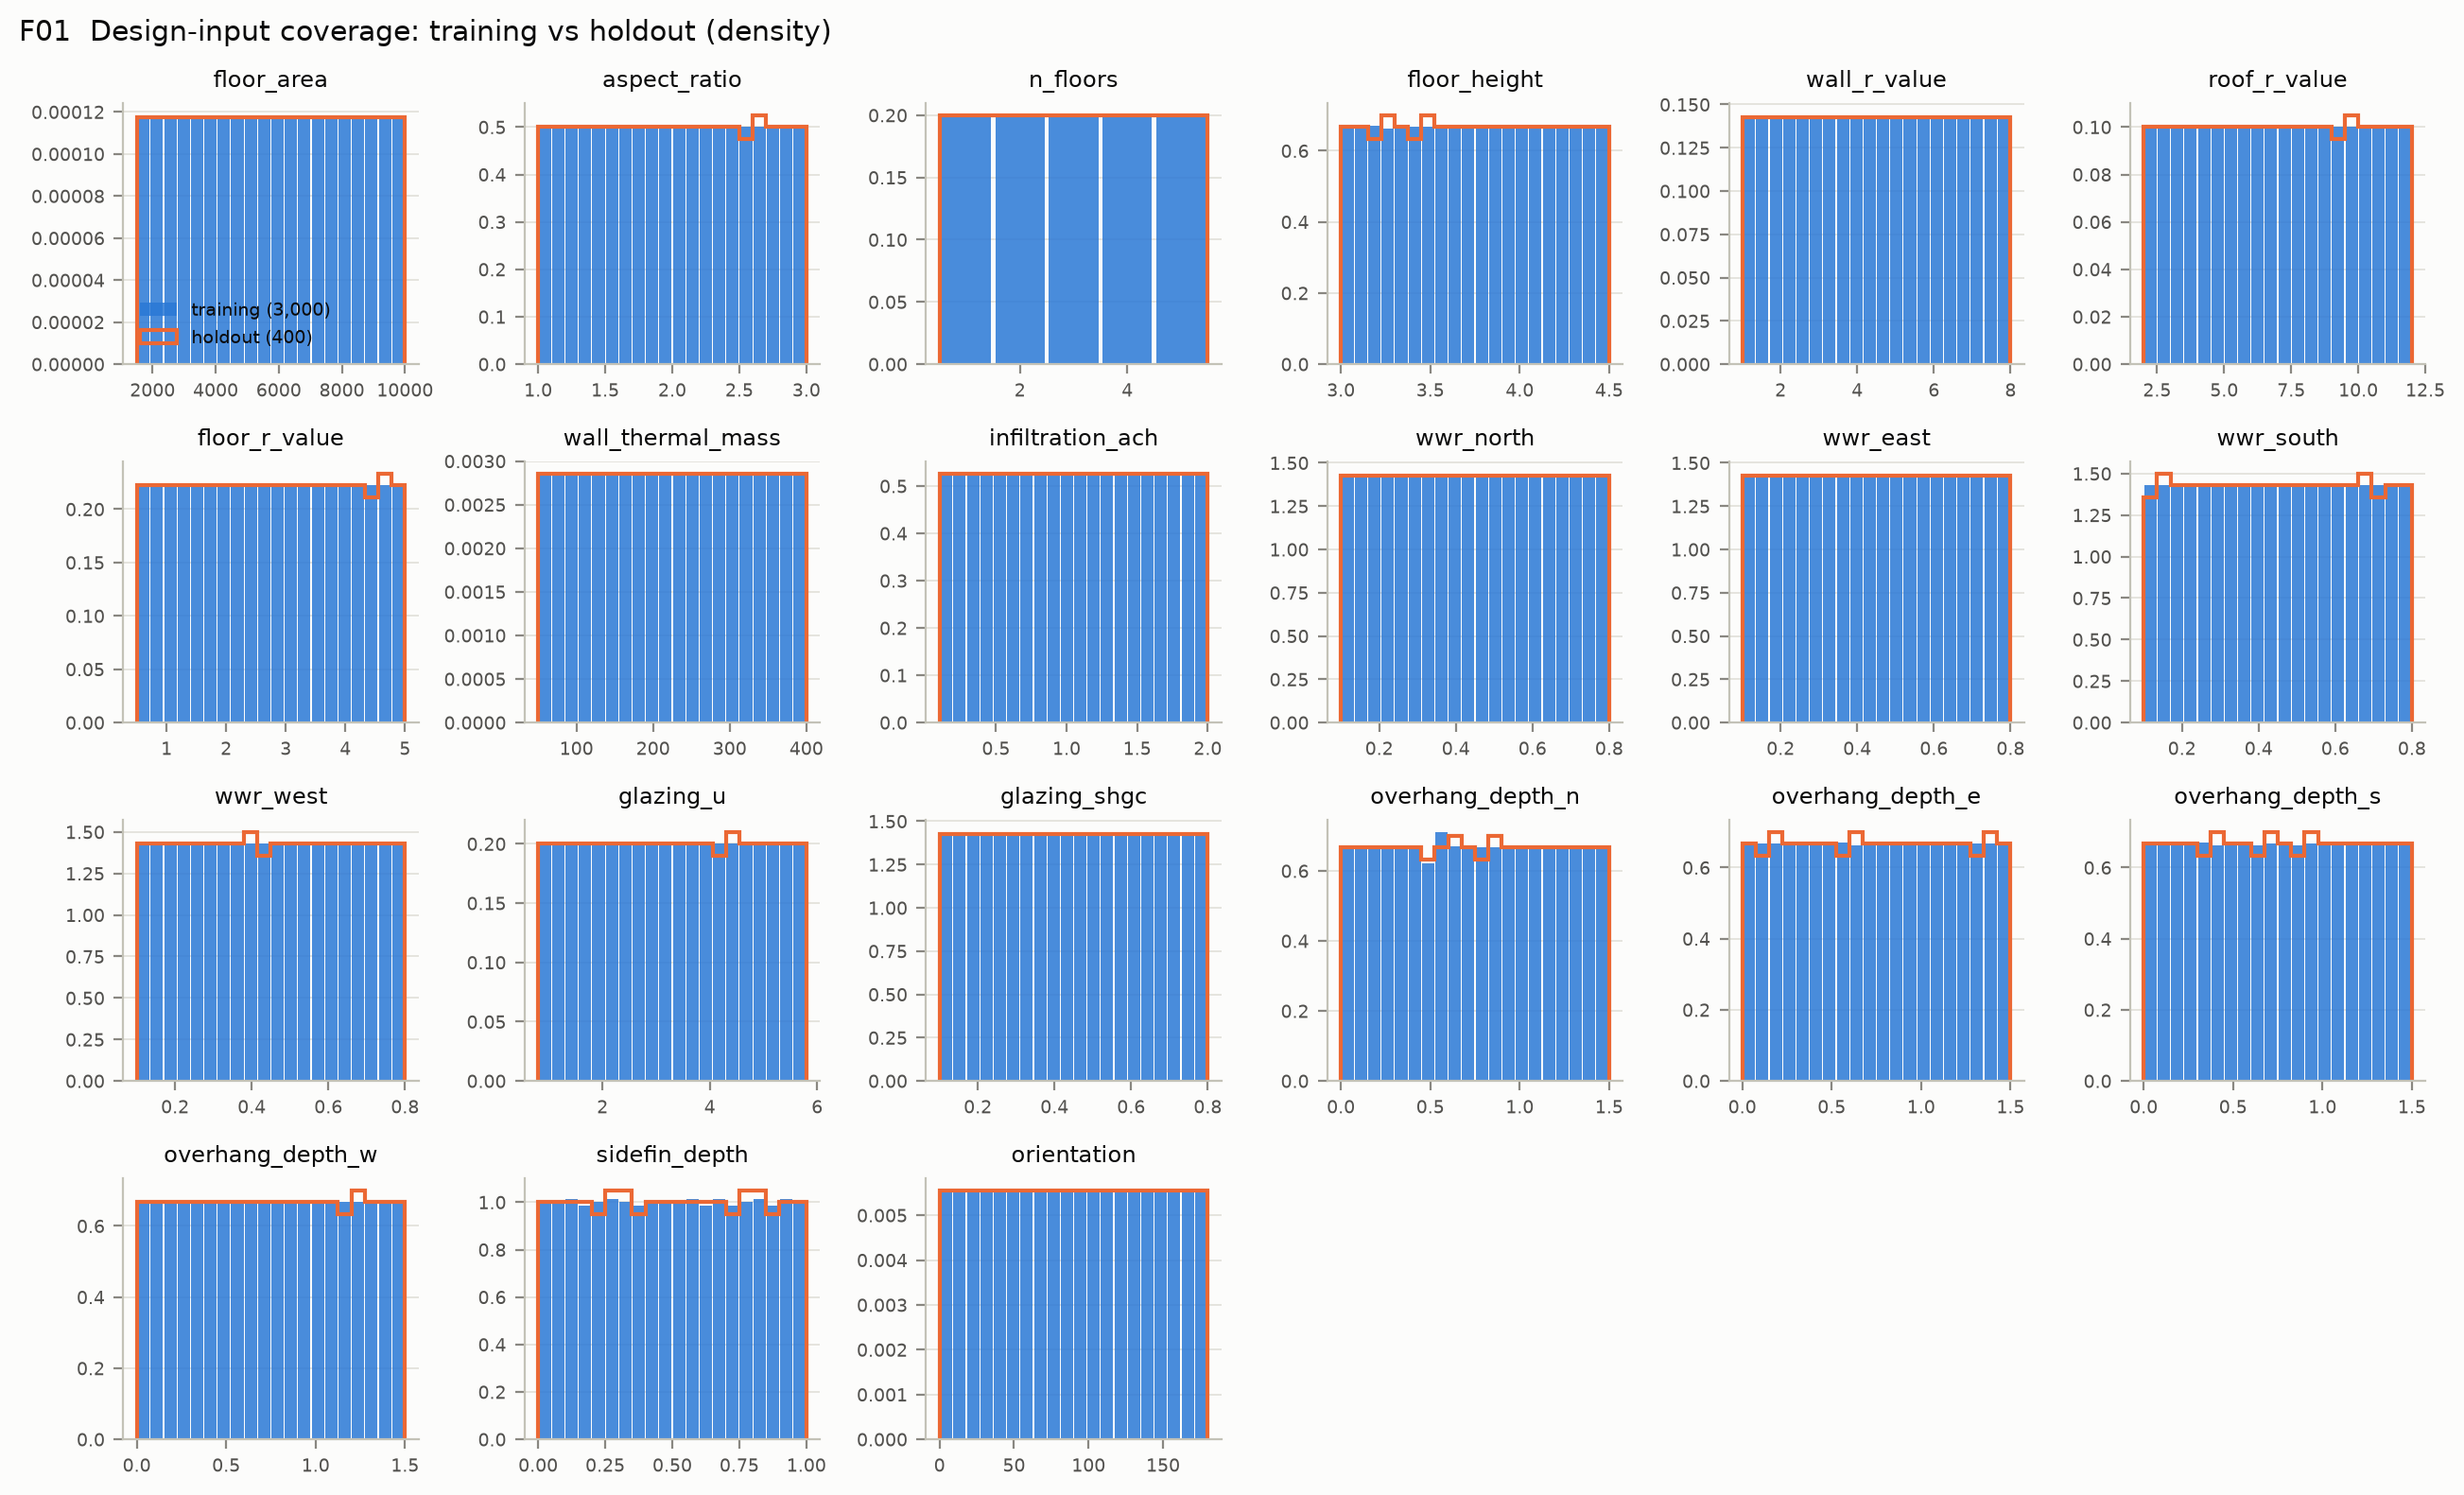

In [3]:
fig("F01_input_histograms", 1200)

**Observation.** All 21 design inputs are flat across their sampled ranges in every climate (C1: 0 of 210 KS/χ² tests reject
uniformity at p < 0.01), and the 400 holdout rows cover the same ranges. `n_floors` has exactly 600 rows per level.

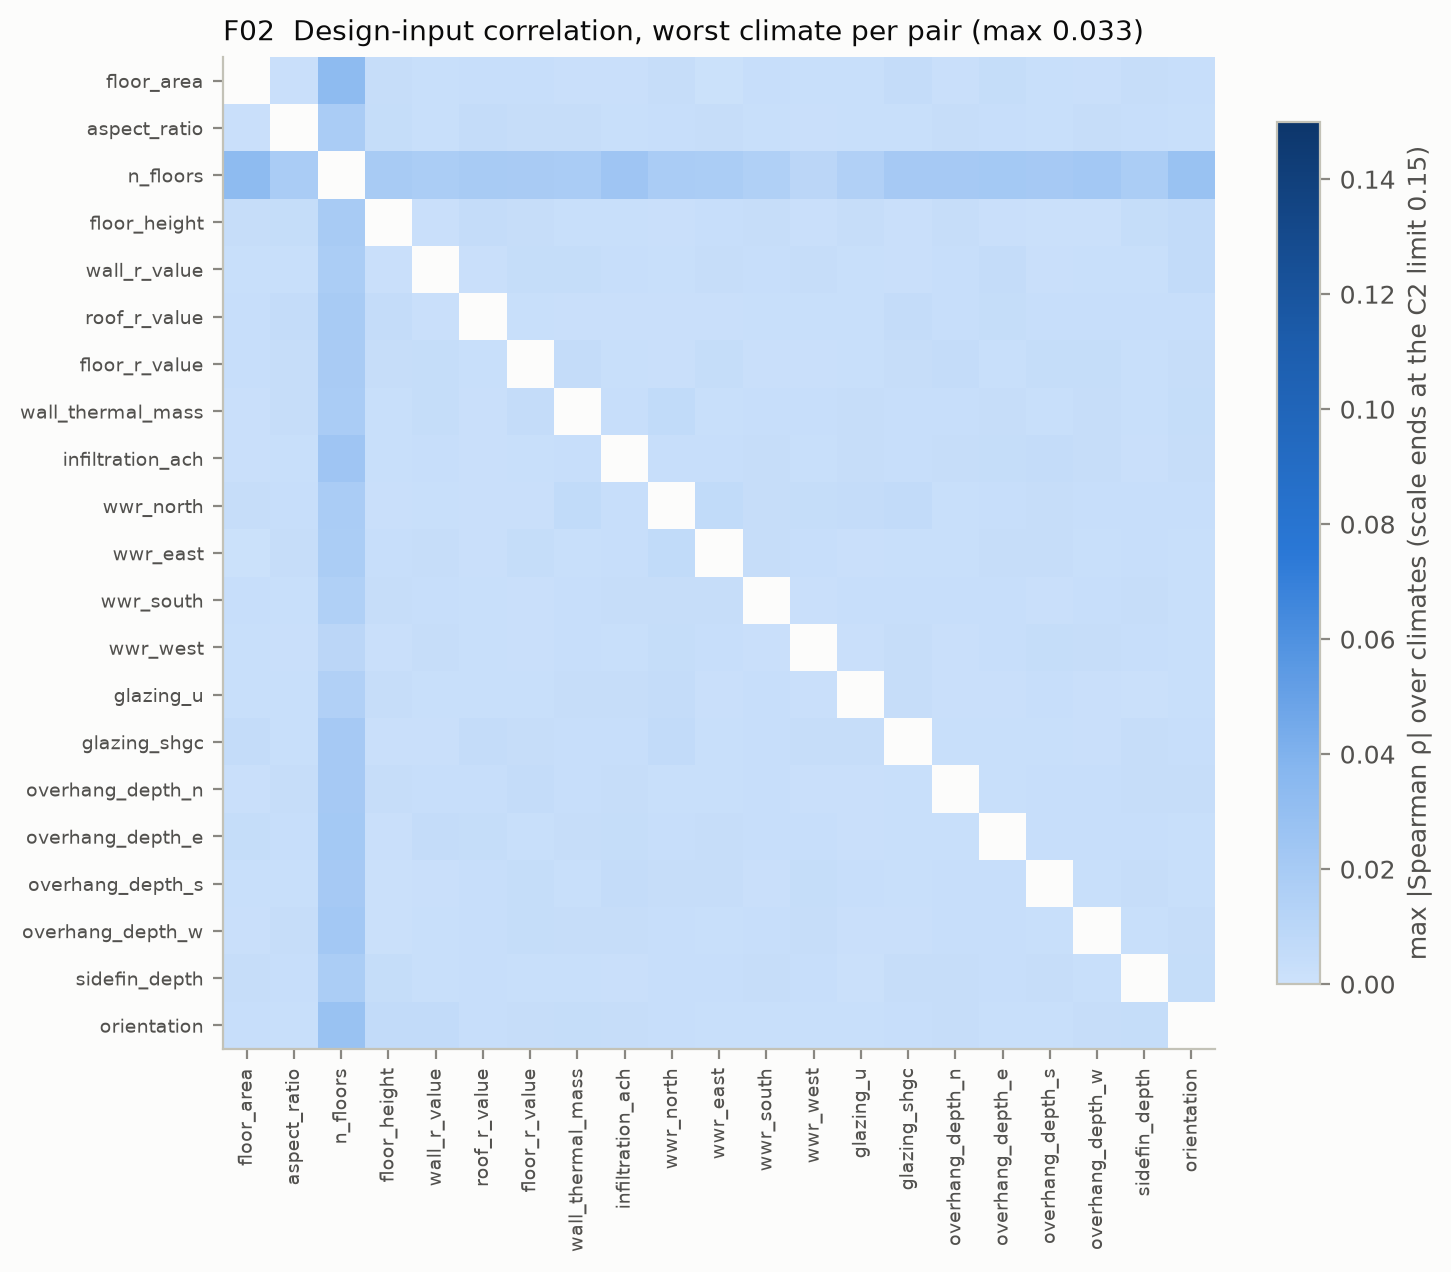

max |rho| per climate:


,climate_key,max_abs_rho,pair,flag
0,atlanta,0.020,n_floors ~ roof_r_value,False
1,chennai,0.027,n_floors ~ orientation,False
2,chicago,0.020,n_floors ~ glazing_shgc,False
3,colombo,0.020,n_floors ~ infiltration_ach,False
4,denver,0.020,n_floors ~ floor_height,False
5,miami,0.018,n_floors ~ wwr_north,False
6,minneapolis,0.024,n_floors ~ infiltration_ach,False
7,new_york,0.021,n_floors ~ overhang_depth_n,False
8,phoenix,0.033,floor_area ~ n_floors,False
9,san_francisco,0.022,n_floors ~ overhang_depth_w,False


In [4]:
fig("F02_input_correlation", 650)
print("max |rho| per climate:"); pd.DataFrame(M["input_corr"])

**Observation.** The largest pairwise Spearman correlation between design inputs in any climate is 0.033 (C2 limit 0.15),
so the 2.4 decorrelation survived the anchor + slice union. The marginal effects in section C and the SHAP attributions in
section E are therefore not confounded by sampling.

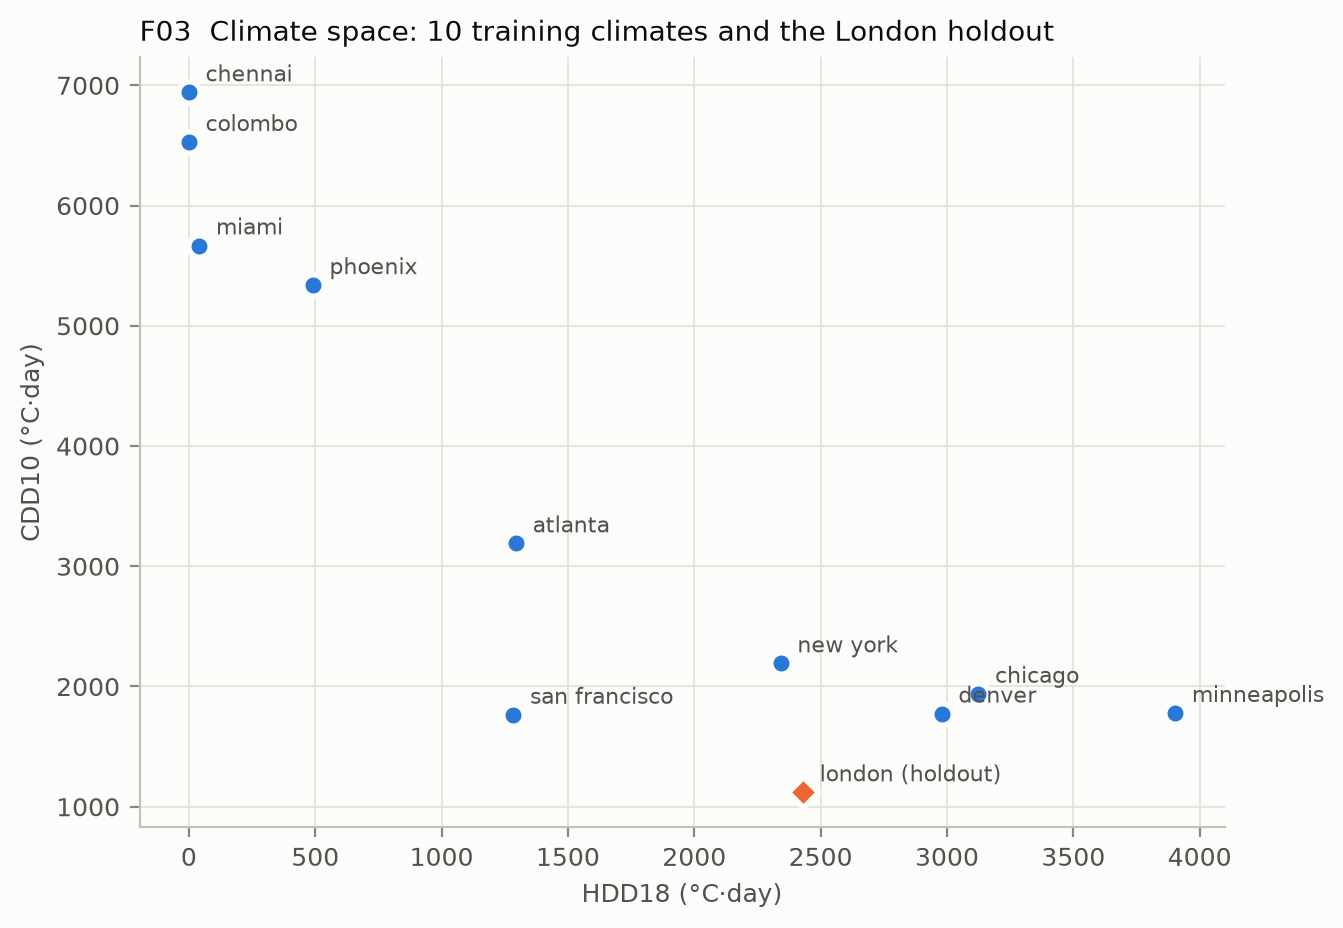

In [5]:
fig("F03_climate_space", 650)

**Observation.** The 7 climate features take only 10 distinct training values and are strongly collinear
(e.g. CDD10 vs mean DBT, ρ ≈ 0.98). London lies outside the training range in CDD10, GHI and latitude, so the
London holdout is an extrapolation test (Phase 3), not interpolation.

## B. Targets

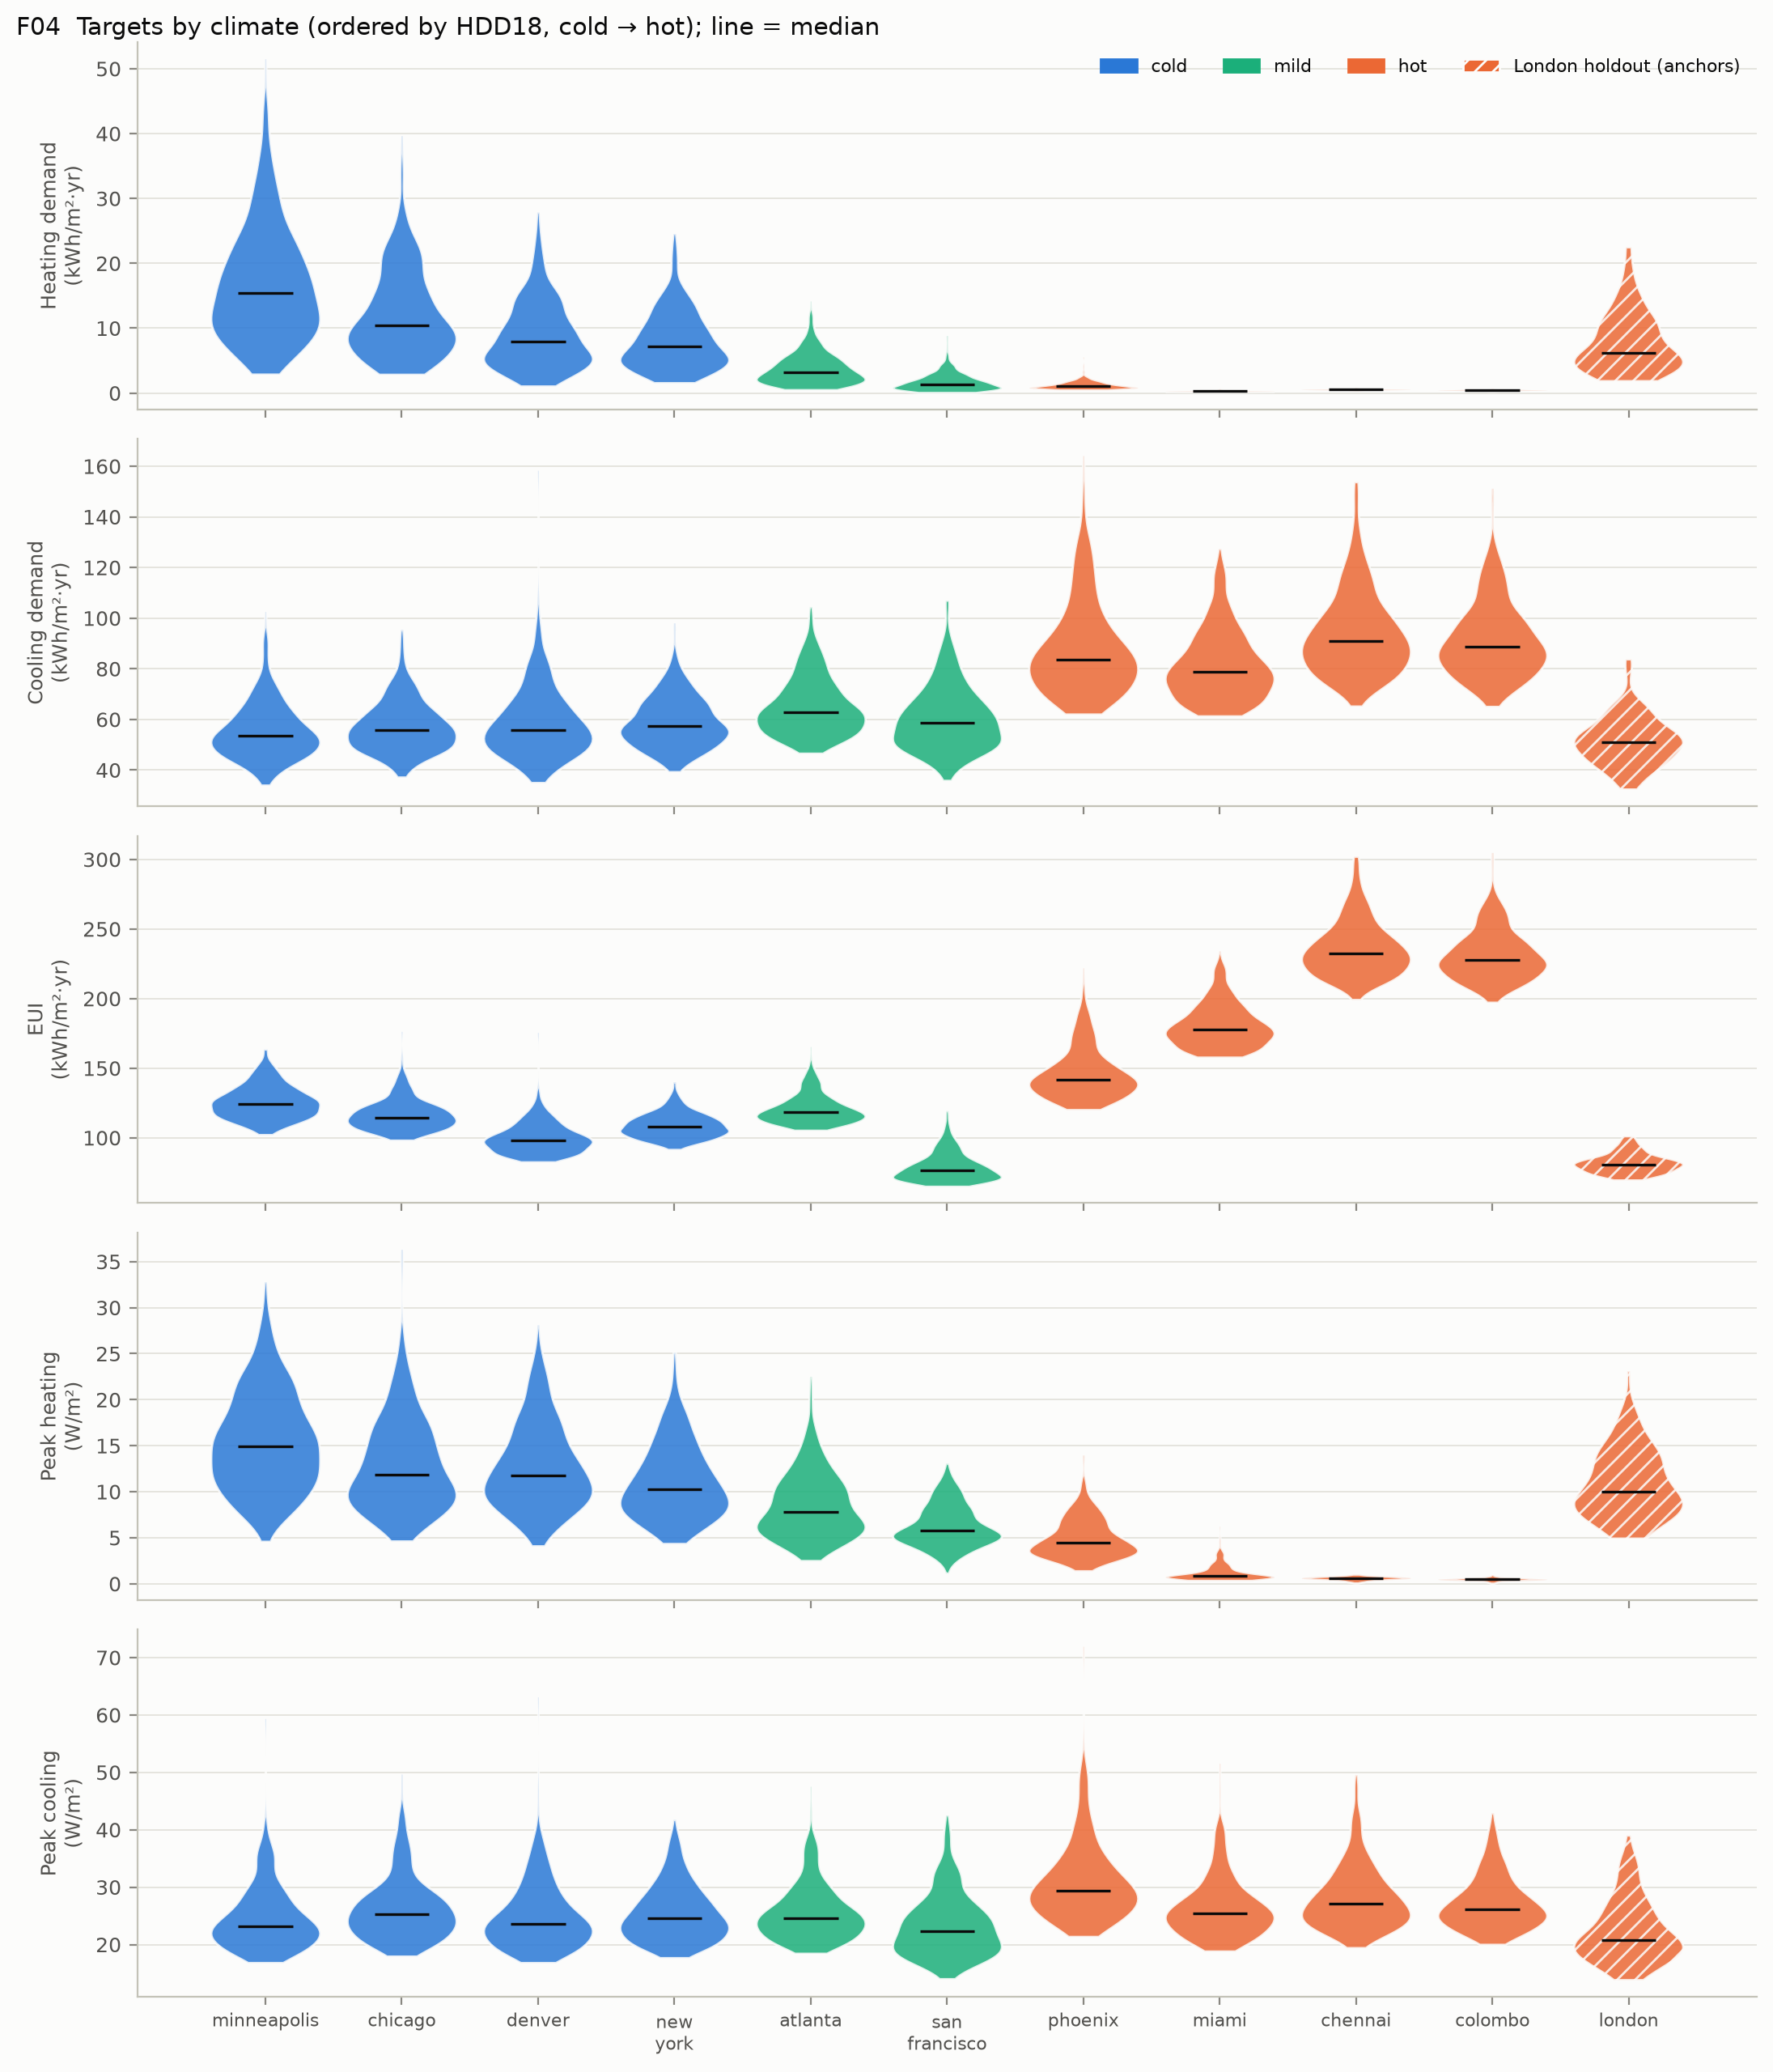

In [6]:
fig("F04_targets_by_climate", 1100)

**Observation.** The distributions follow climate as expected: heating is negligible in Chennai, Colombo and Miami
(medians 0.3–0.6 kWh/m²) and largest in Minneapolis (15.5); cooling and EUI are highest in the humid tropics (EUI ≈ 230 kWh/m²).
London (anchor designs only, hatched) has heating similar to New York and the lowest cooling of all, which confirms it as an
extrapolation case for Phase 3.

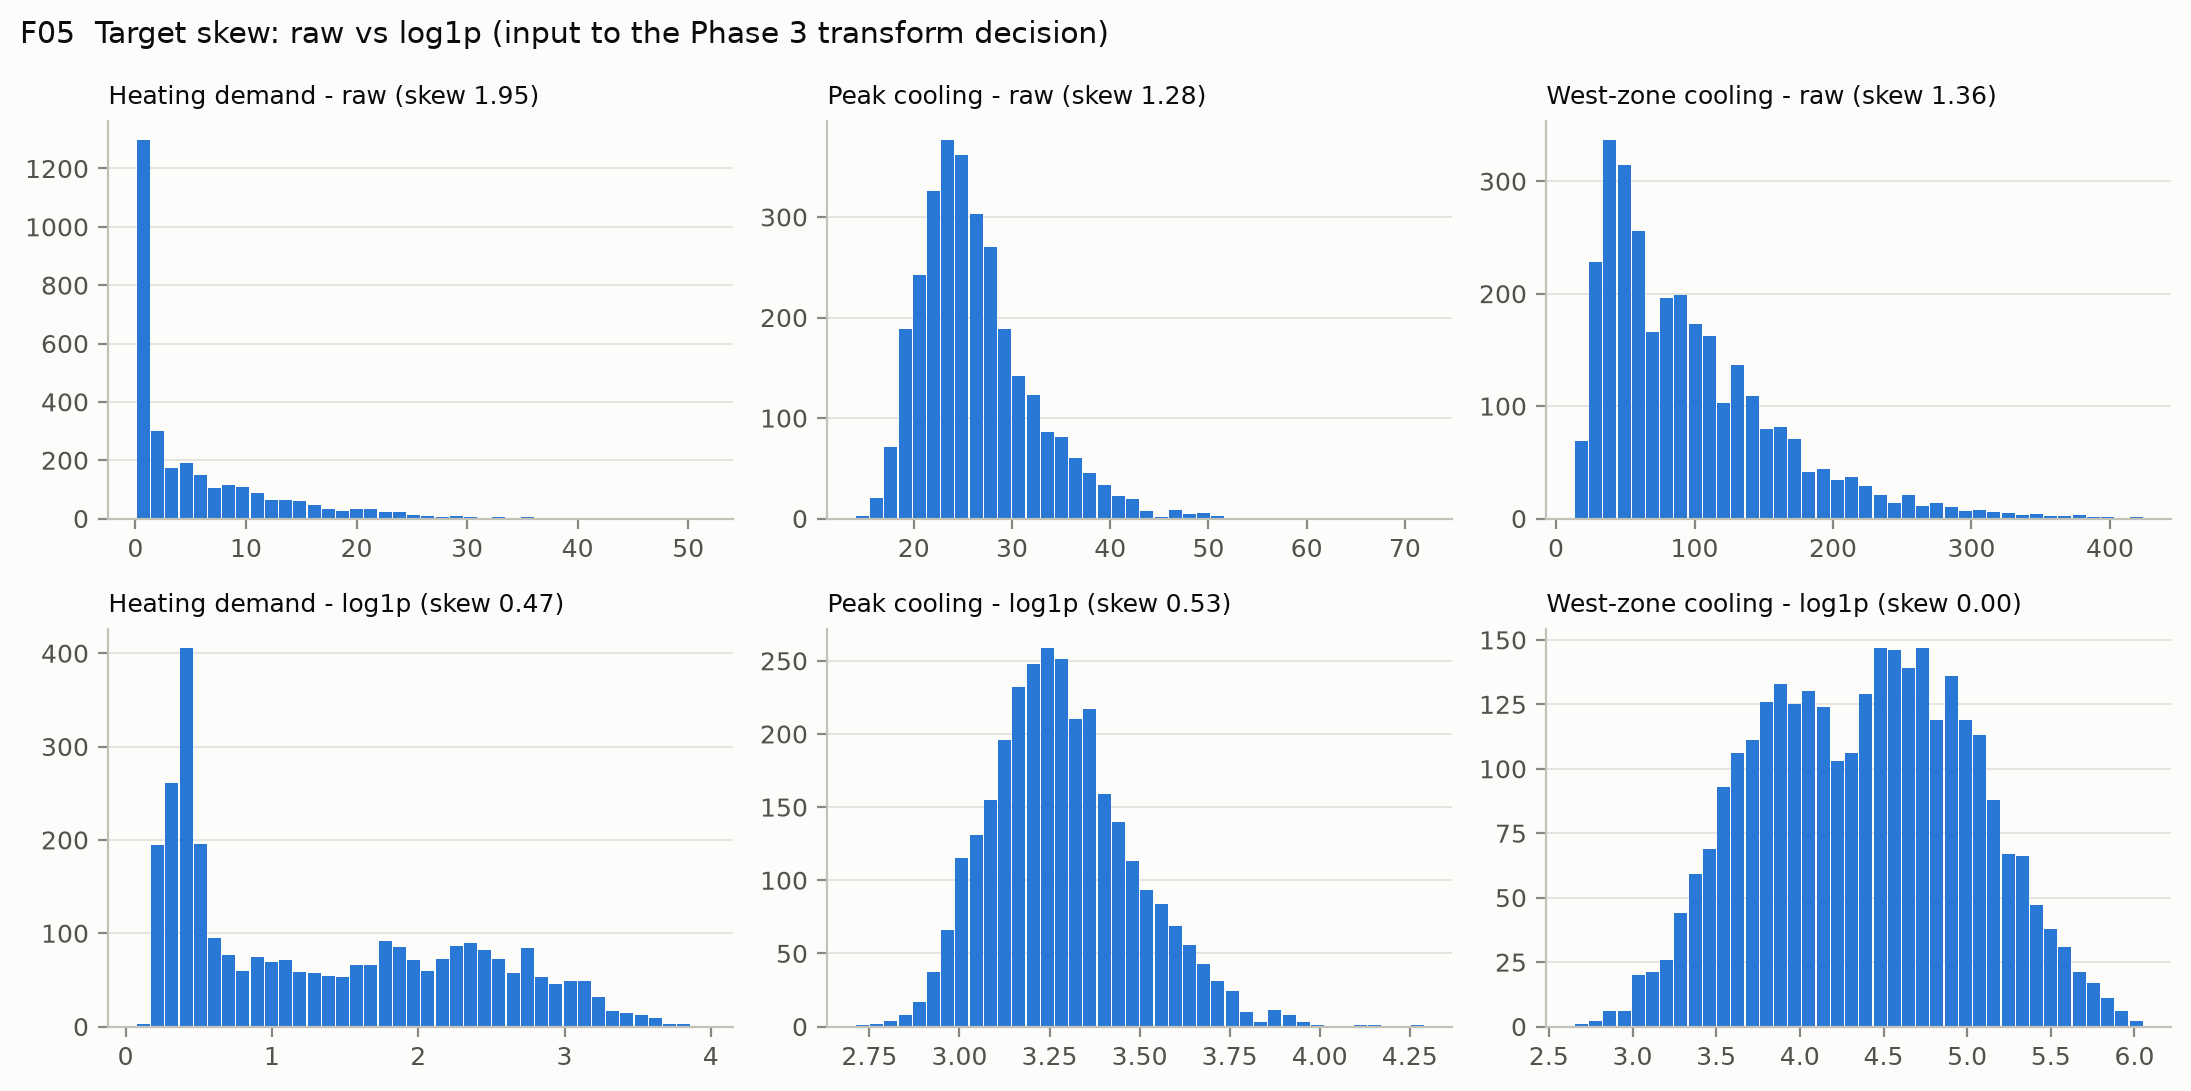

In [7]:
fig("F05_target_transforms", 1000)

**Observation.** Heating is strongly right-skewed (skew ≈ 2); `log1p` makes it nearly symmetric. Perimeter-zone cooling
and peak cooling are moderately skewed (≈ 1.2–1.4). Phase 3 should test training on `log1p(heating)`, with errors reported back in kWh/m².

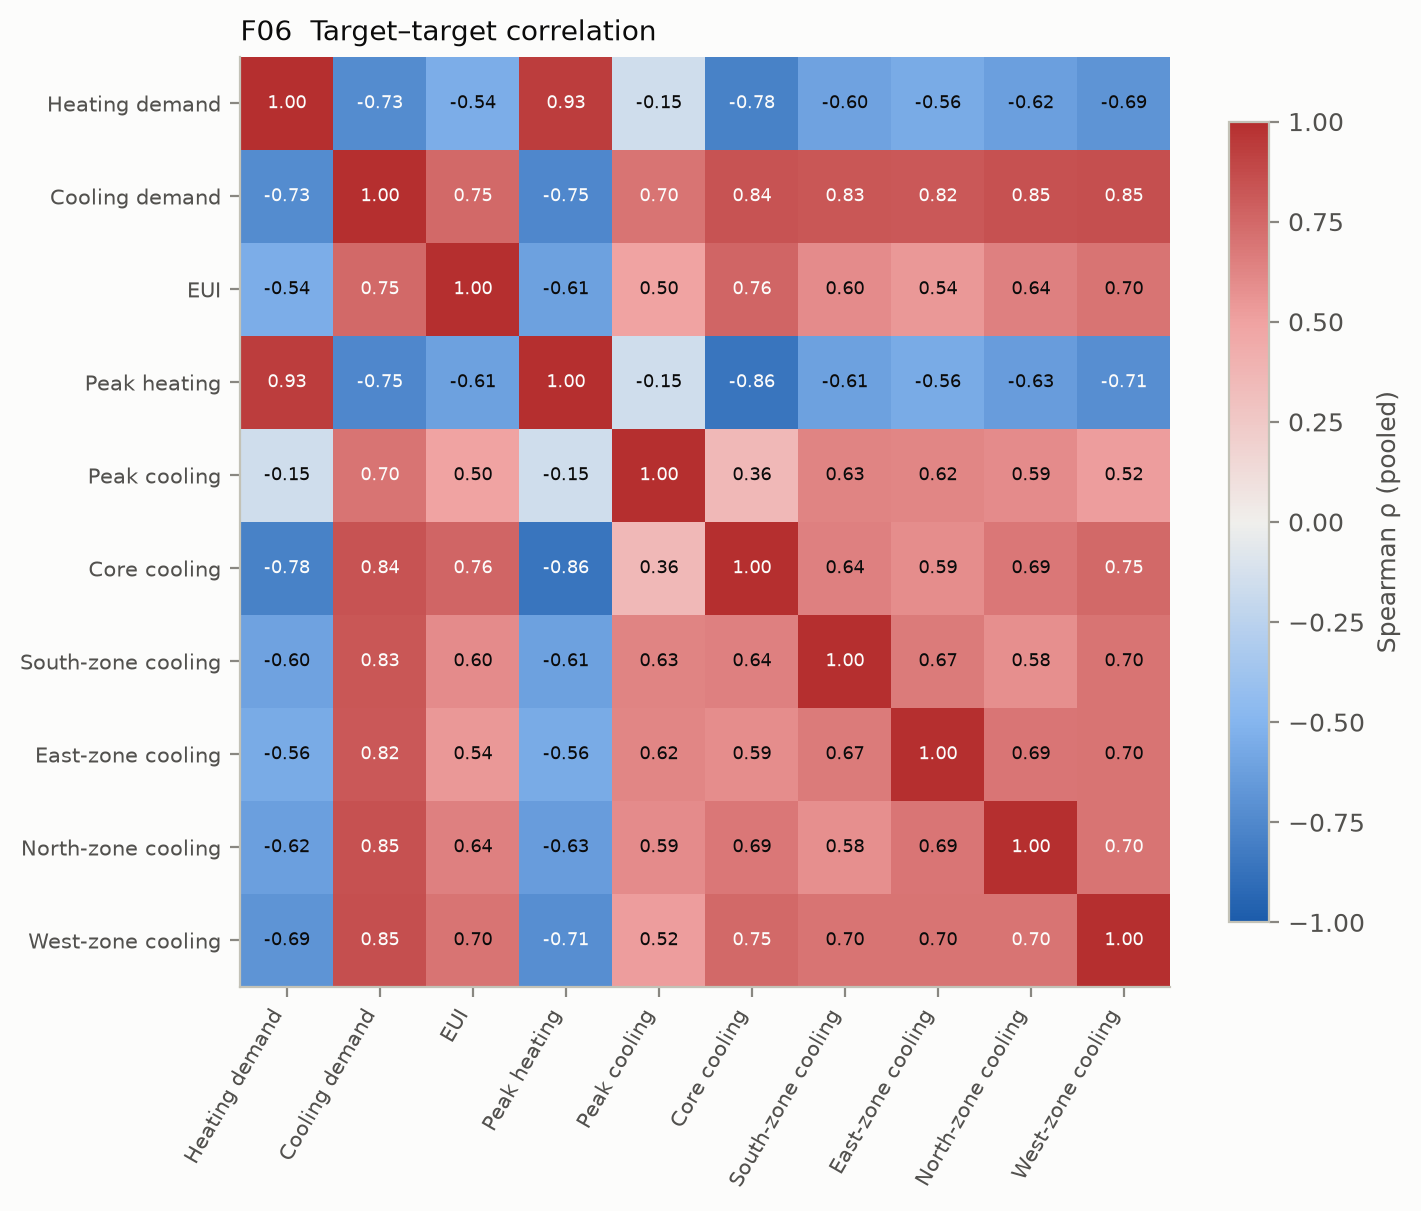

In [8]:
fig("F06_target_correlation", 650)

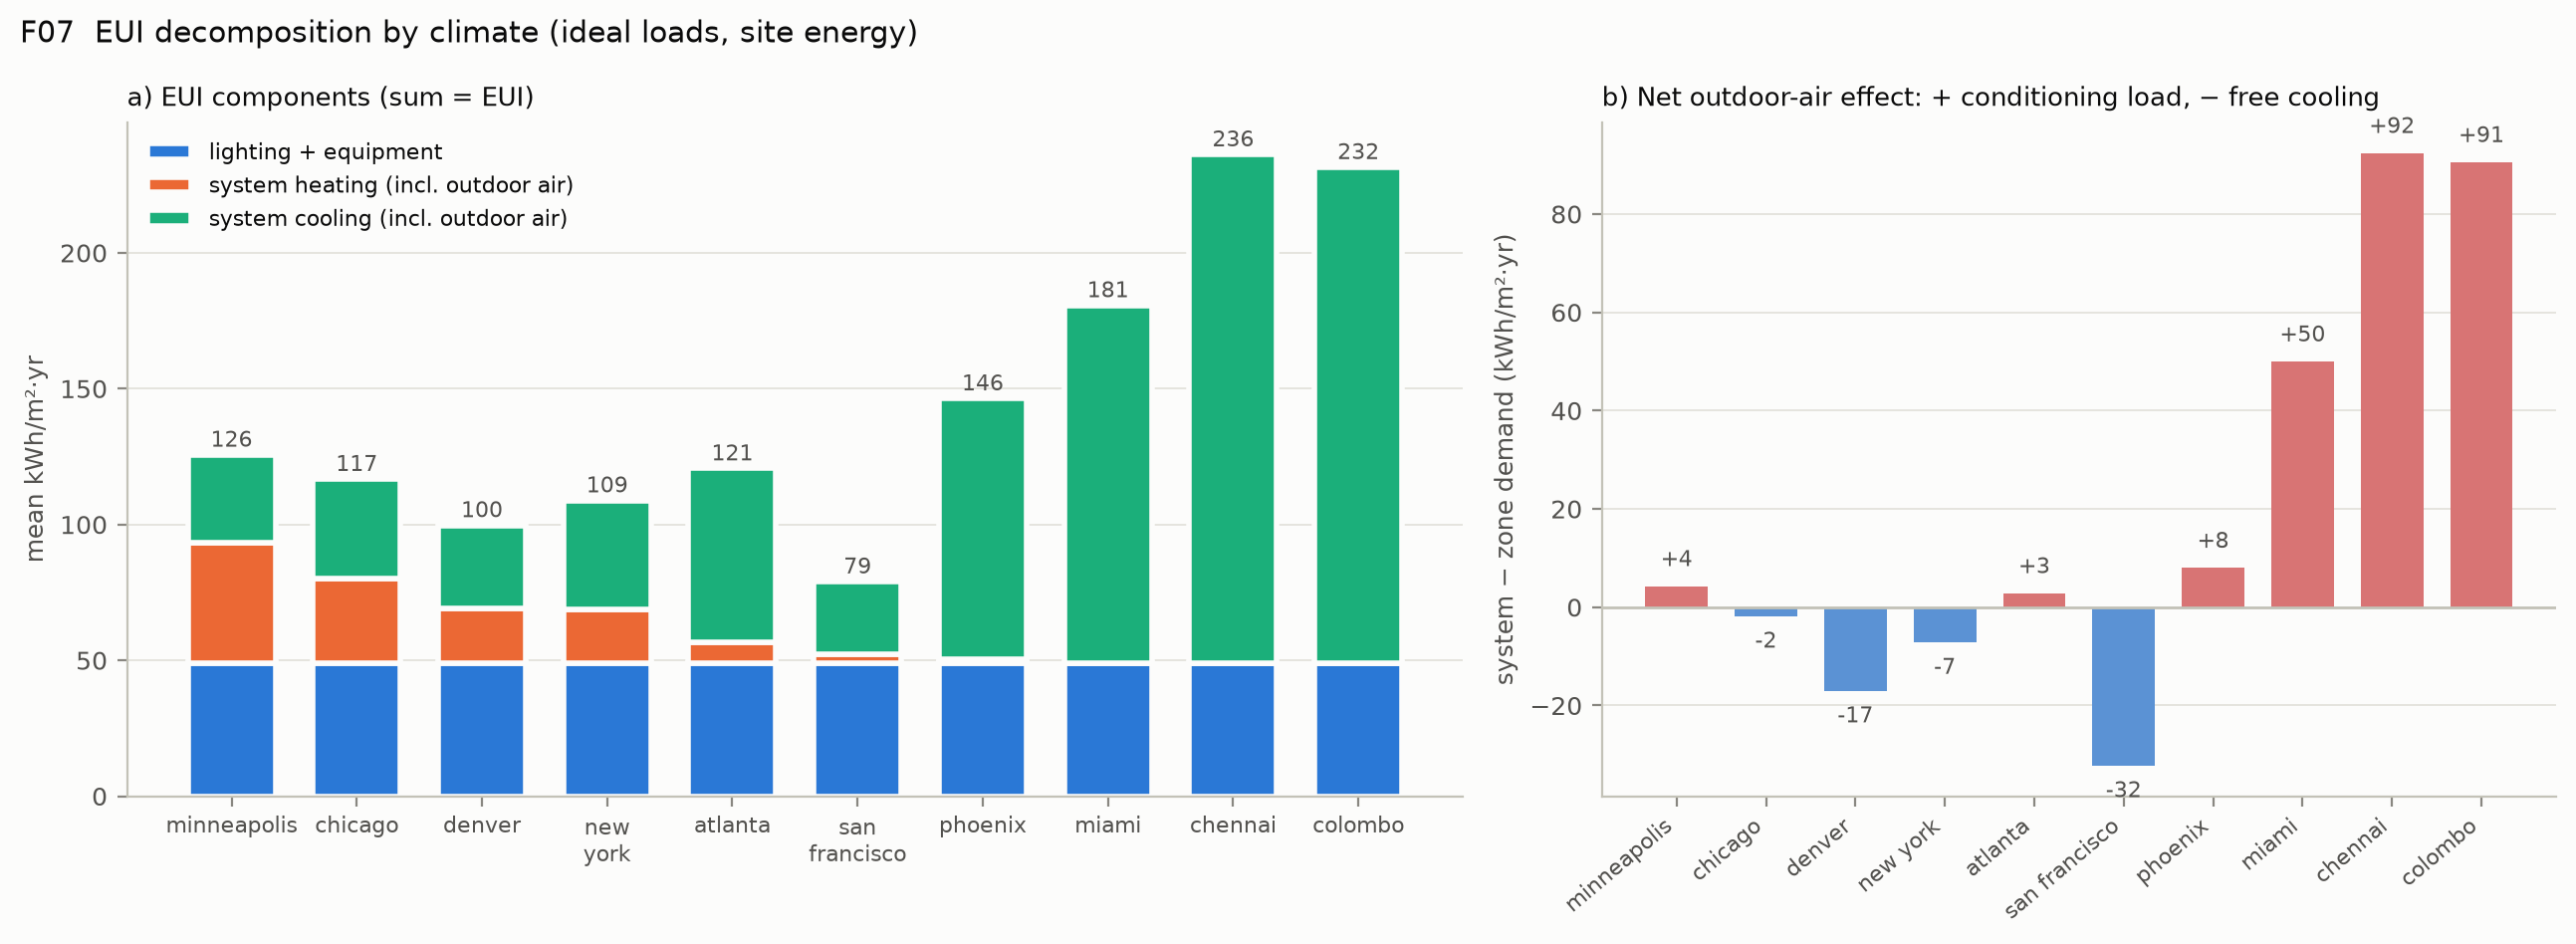

,elec_kwh_m2,sys_heat_kwh_m2,sys_cool_kwh_m2,heating_demand_kwh_m2,cooling_demand_kwh_m2,oa_net,eui_kwh_m2,closure
minneapolis,48.87,44.42,32.37,16.98,55.51,4.29,125.65,-0.0
chicago,48.87,31.10,36.74,12.31,57.32,-1.80,116.71,0.0
denver,48.87,20.10,30.73,8.91,58.93,-17.01,99.70,0.0
new_york,48.87,19.80,40.16,8.10,59.00,-7.14,108.83,0.0
atlanta,48.87,7.82,63.92,3.74,65.15,2.85,120.61,0.0
san_francisco,48.87,3.26,26.85,1.72,60.60,-32.22,78.98,0.0
phoenix,48.87,1.55,95.95,1.21,88.29,8.01,146.37,0.0
miami,48.87,0.04,131.75,0.31,81.48,50.01,180.66,-0.0
chennai,48.87,0.00,187.34,0.56,94.36,92.42,236.20,0.0
colombo,48.87,0.00,182.65,0.47,91.63,90.55,231.52,0.0


In [9]:
fig("F07_eui_decomposition", 1150)
pd.DataFrame(M["eui_decomposition"]).T

**Observation (thesis caveat; corrects the 2.7 note).** EUI = lighting/equipment (48.9 kWh/m², identical everywhere) +
*system* heating + *system* cooling, closing to < 0.1 kWh/m² in every climate. The system terms include outdoor air (OA), and its net
effect changes sign with climate: about +91 kWh/m² in Chennai and Colombo and +50 in Miami for dehumidifying and cooling humid OA,
but −32 in San Francisco and −17 in Denver, where OA provides free cooling. The zone-demand targets (Decision A) exclude this; EUI
includes it. EUI is therefore not "heating + cooling demand + lighting", and must be described as ideal-loads site energy in the thesis.

## C. Physics directions

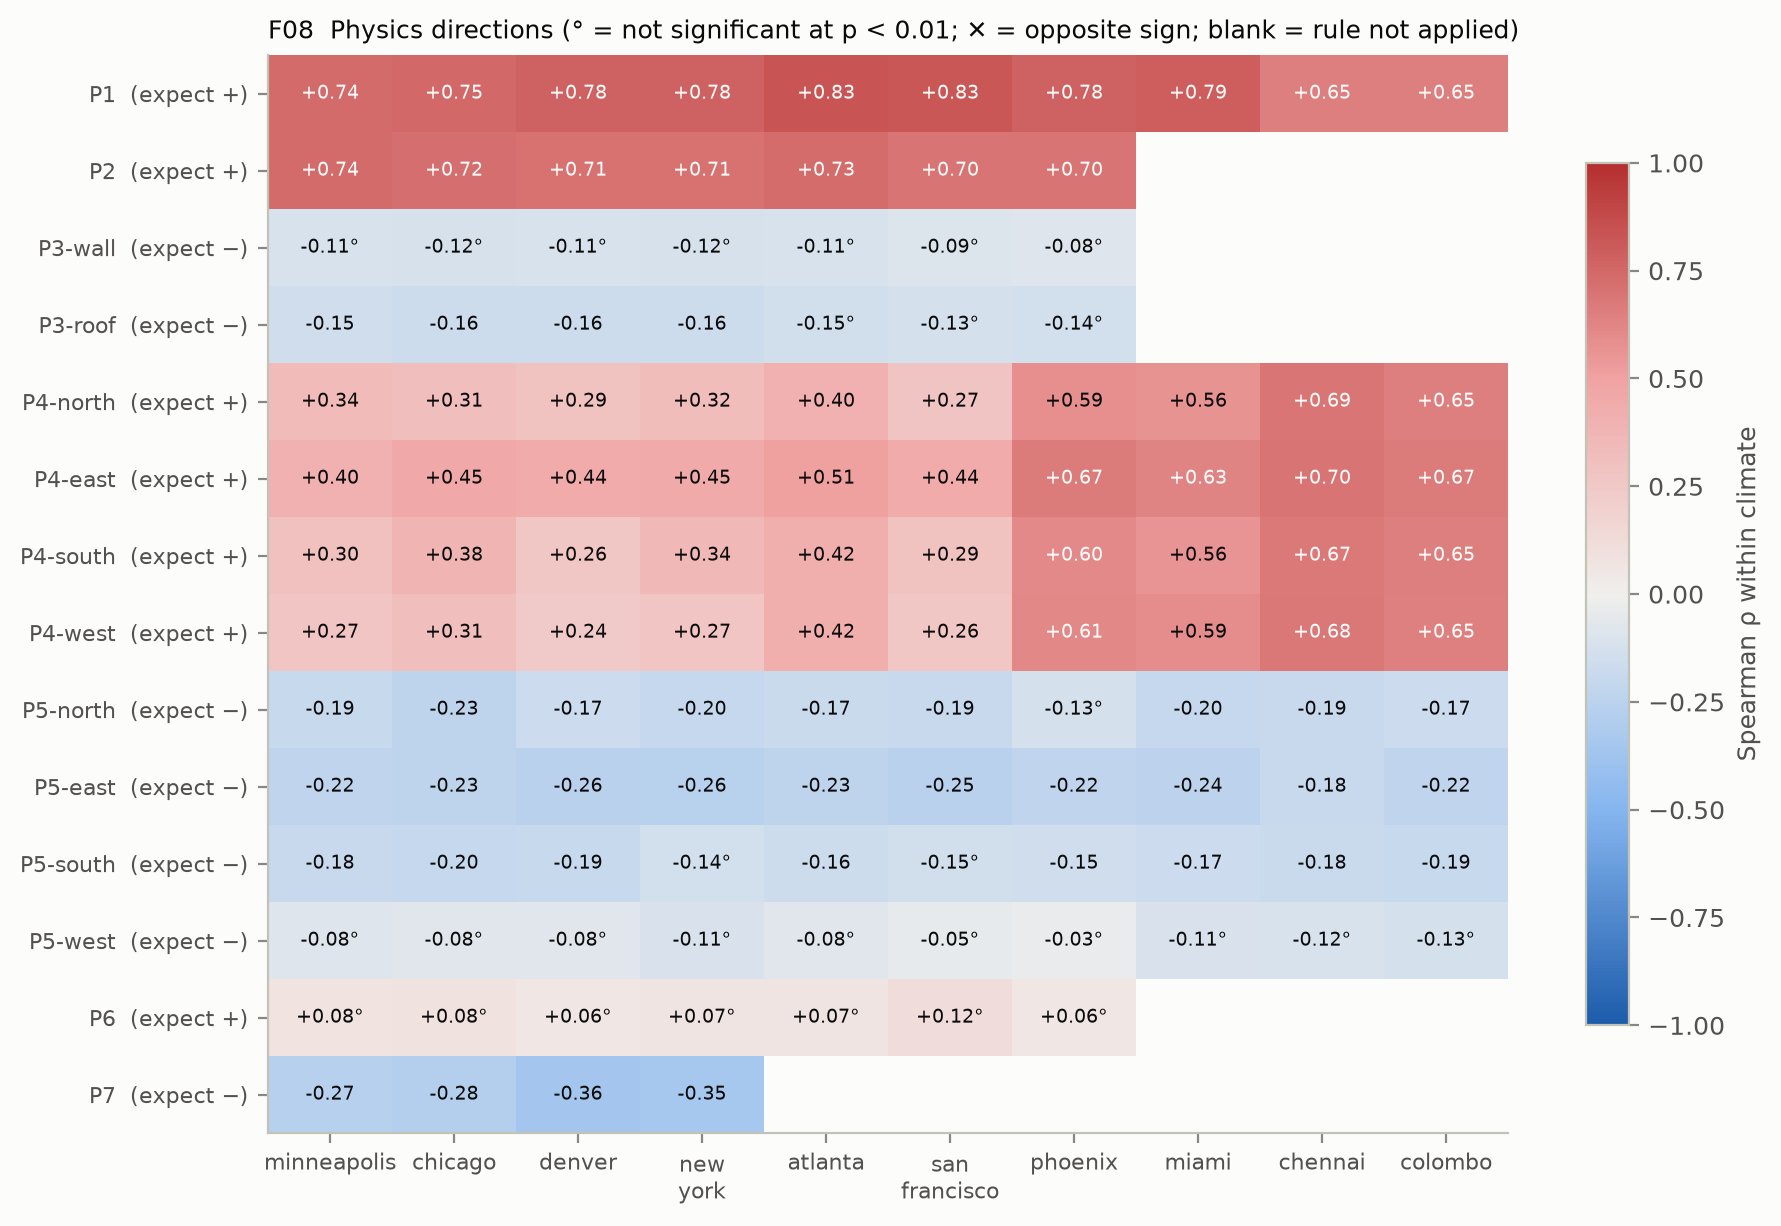

,rule,severity,status,opposite,weak,rho_min,rho_max
0,P1,FAIL,PASS,[],[],0.649,0.829
1,P2,FAIL,PASS,[],[],0.697,0.740
2,P3-wall,FAIL,WARN,[],"[atlanta, chicago, denver, minneapolis, new_york, phoenix, san_francisco]",-0.122,-0.085
3,P3-roof,FAIL,WARN,[],"[atlanta, phoenix, san_francisco]",-0.158,-0.129
4,P4-north,FAIL,PASS,[],[],0.275,0.689
5,P4-east,FAIL,PASS,[],[],0.403,0.697
6,P4-south,FAIL,PASS,[],[],0.265,0.673
7,P4-west,FAIL,PASS,[],[],0.239,0.683
8,P5-north,WARN,INFO,[],[phoenix],-0.229,-0.132
9,P5-east,WARN,PASS,[],[],-0.260,-0.183


In [10]:
fig("F08_physics_directions", 1100)
pd.DataFrame(M["physics_status"])

**Observation.** Every strong relation holds in every applicable climate: SHGC raises cooling (ρ 0.65–0.83), glazing U raises
heating (ρ 0.70–0.74), SHGC lowers heating in cold climates (ρ −0.27 to −0.36), and each façade's WWR raises the cooling of its *own*
zone (P4, all four façades, ρ 0.24–0.70), which confirms the façade → zone wiring. No relation has the opposite sign anywhere.

The weak relations have physical explanations, not data faults:
- **Wall R-value → heating (P3-wall, ρ ≈ −0.1, WARN):** floor plates are 1,500–10,000 m² per storey, so opaque wall area is small
  relative to floor area, and glazing (U up to 5.8, WWR up to 0.8) dominates envelope heat loss.
- **Roof R-value → heating (P3-roof, WARN):** significant (ρ ≈ −0.15 to −0.16) in the four cold climates, not in Atlanta,
  Phoenix or San Francisco, where heating itself is small; the roof's share of the envelope is also diluted by up to 5 floors.
- **West overhang (P5-west, INFO):** façade names are building-relative and orientation spans 0–180°, so the "west" façade only ever
  faces W, NW, N, NE or E, never south, where overhangs work best.
- **Infiltration (P6, INFO):** small effect, as expected from the 2.6 OAT test.

In [11]:
pd.DataFrame(M["core_roof"])

,climate_key,subset,n,rho,p,core_cooling_median
0,chennai,n_floors=1,60,-0.956,1.139e-32,70.661
1,chennai,n_floors>=2,240,-0.652,1.976e-30,63.800
2,colombo,n_floors=1,60,-0.952,1.781e-31,70.119
3,colombo,n_floors>=2,240,-0.739,9.159e-43,63.776
4,miami,n_floors=1,60,-0.903,5.806e-23,62.901
5,miami,n_floors>=2,240,-0.458,7.304e-14,60.030
6,phoenix,n_floors=1,60,-0.779,2.440e-13,61.082
7,phoenix,n_floors>=2,240,-0.421,9.426e-12,59.779


**Observation.** Roof insulation affects core-zone cooling far more in single-storey buildings (ρ ≈ −0.78 to −0.96) than in
multi-storey ones (ρ ≈ −0.42 to −0.74): with one floor the windowless core sits directly under the roof. This explains the 2.7
core-cooling outliers and is an interaction the surrogate must capture (Phase 3 feature: roof exposure for `n_floors = 1`).

## D. Orientation

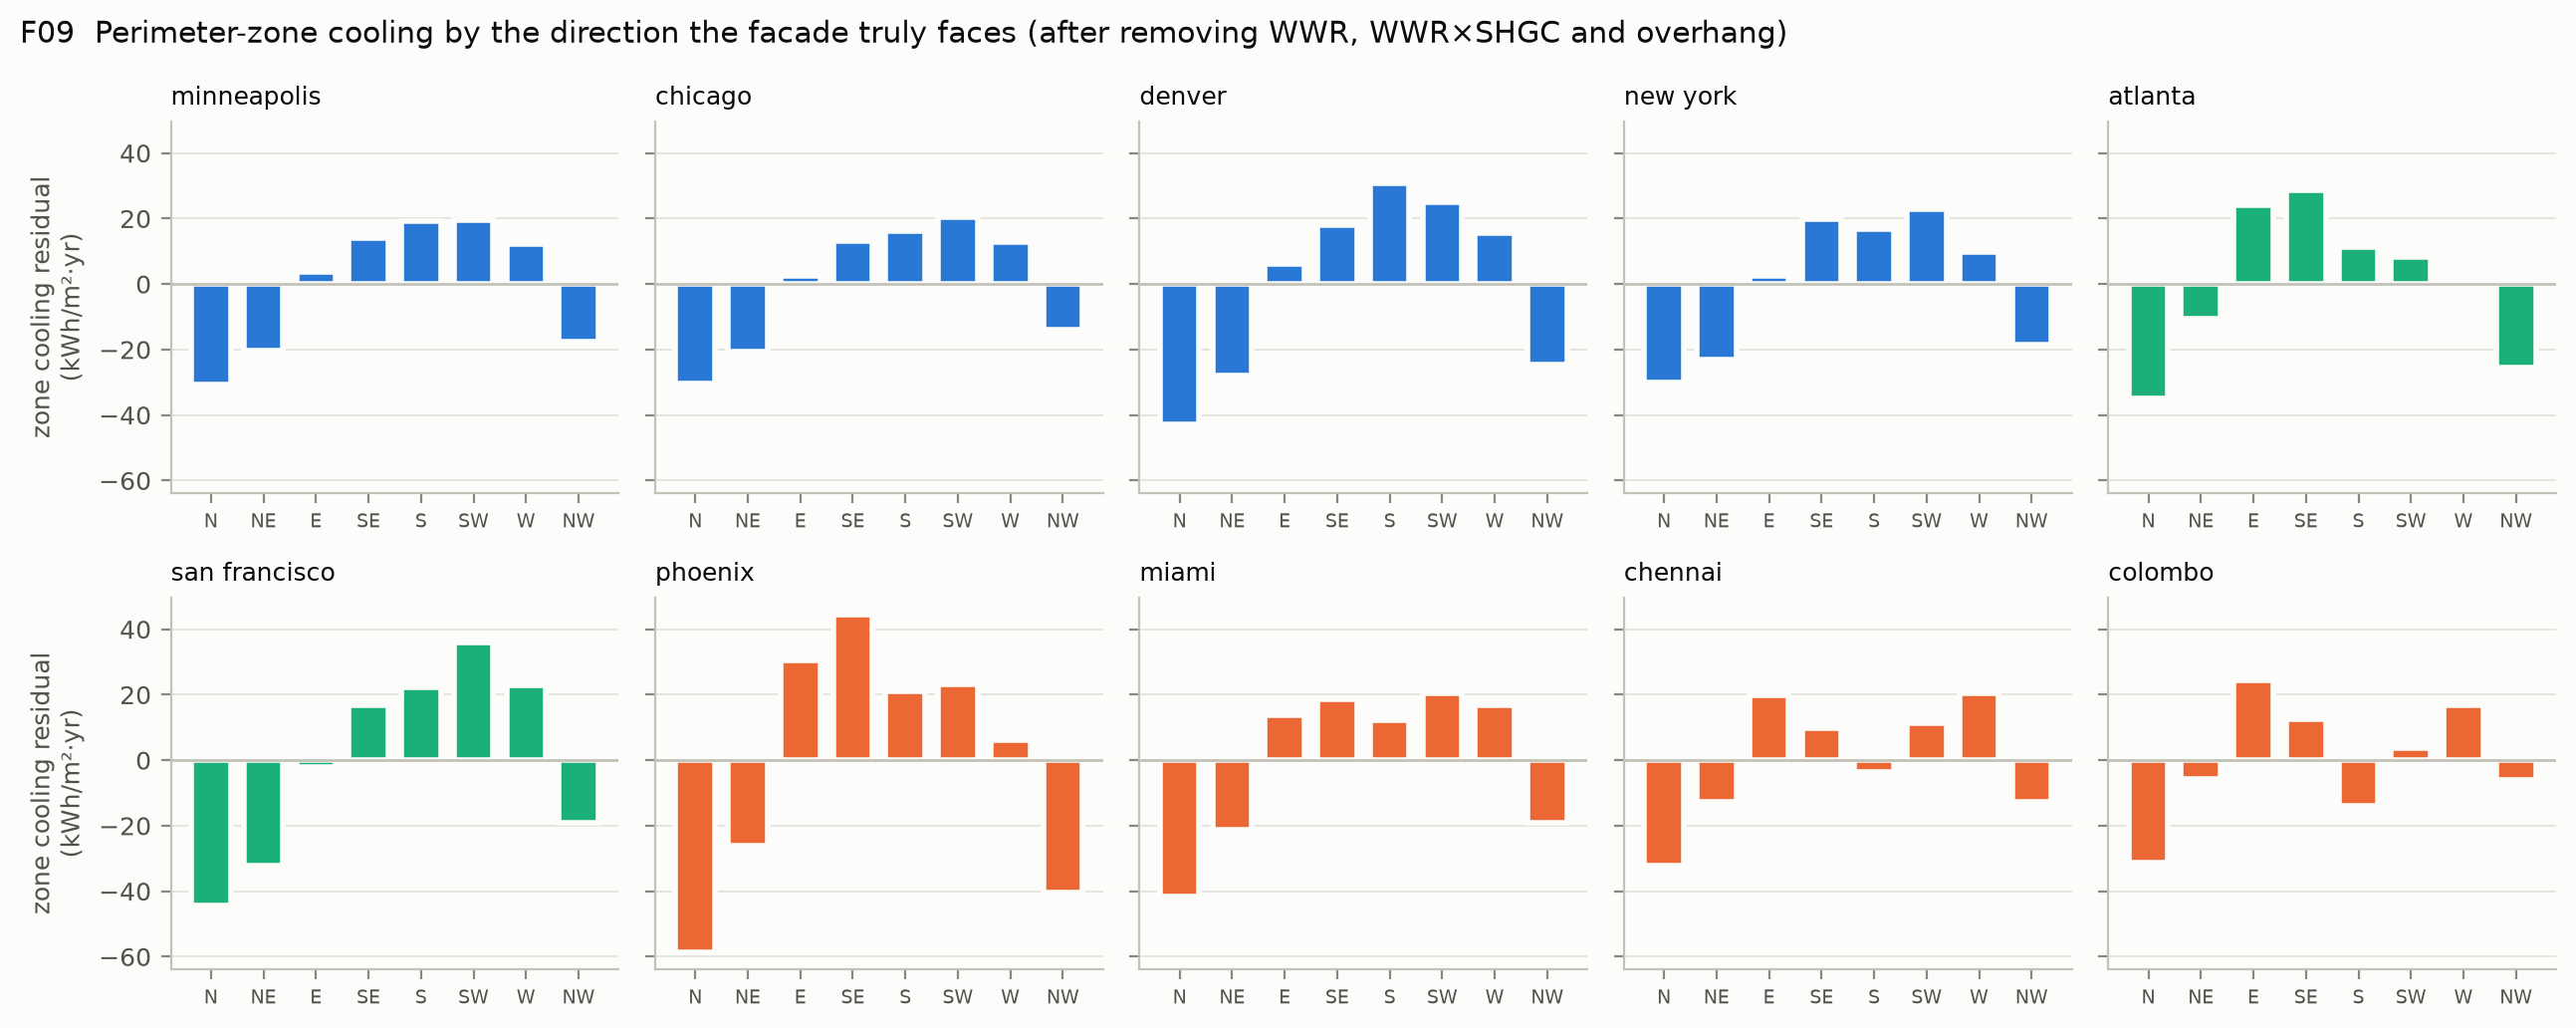

,climate_key,latitude,applies,mean_resid_W_SW,mean_resid_N,pass
0,atlanta,33.630,True,3.453,-35.043,True
1,chennai,12.994,False,15.861,-32.326,None
2,chicago,41.960,True,16.665,-30.317,True
3,colombo,6.905,False,10.140,-31.189,None
4,denver,39.833,True,20.275,-42.908,True
5,miami,25.755,True,18.641,-41.571,True
6,minneapolis,44.883,True,15.751,-30.579,True
7,new_york,40.779,True,16.325,-30.019,True
8,phoenix,33.428,True,14.687,-58.709,True
9,san_francisco,37.620,True,29.408,-44.384,True


In [12]:
fig("F09_facade_azimuth", 1200)
pd.DataFrame(M["facade"])[["climate_key", "latitude", "applies", "mean_resid_W_SW", "mean_resid_N", "pass"]]

**Observation.** After removing window size, glass and overhang, north-facing façades have the lowest cooling in every climate,
and E–SE–S–SW–W façades the highest (O1 passes in 8 of 8 climates north of 25°). Near the equator (Colombo, Chennai) south-facing
façades are no longer high, because the sun is overhead or to the north for part of the year. Orientation is captured correctly.

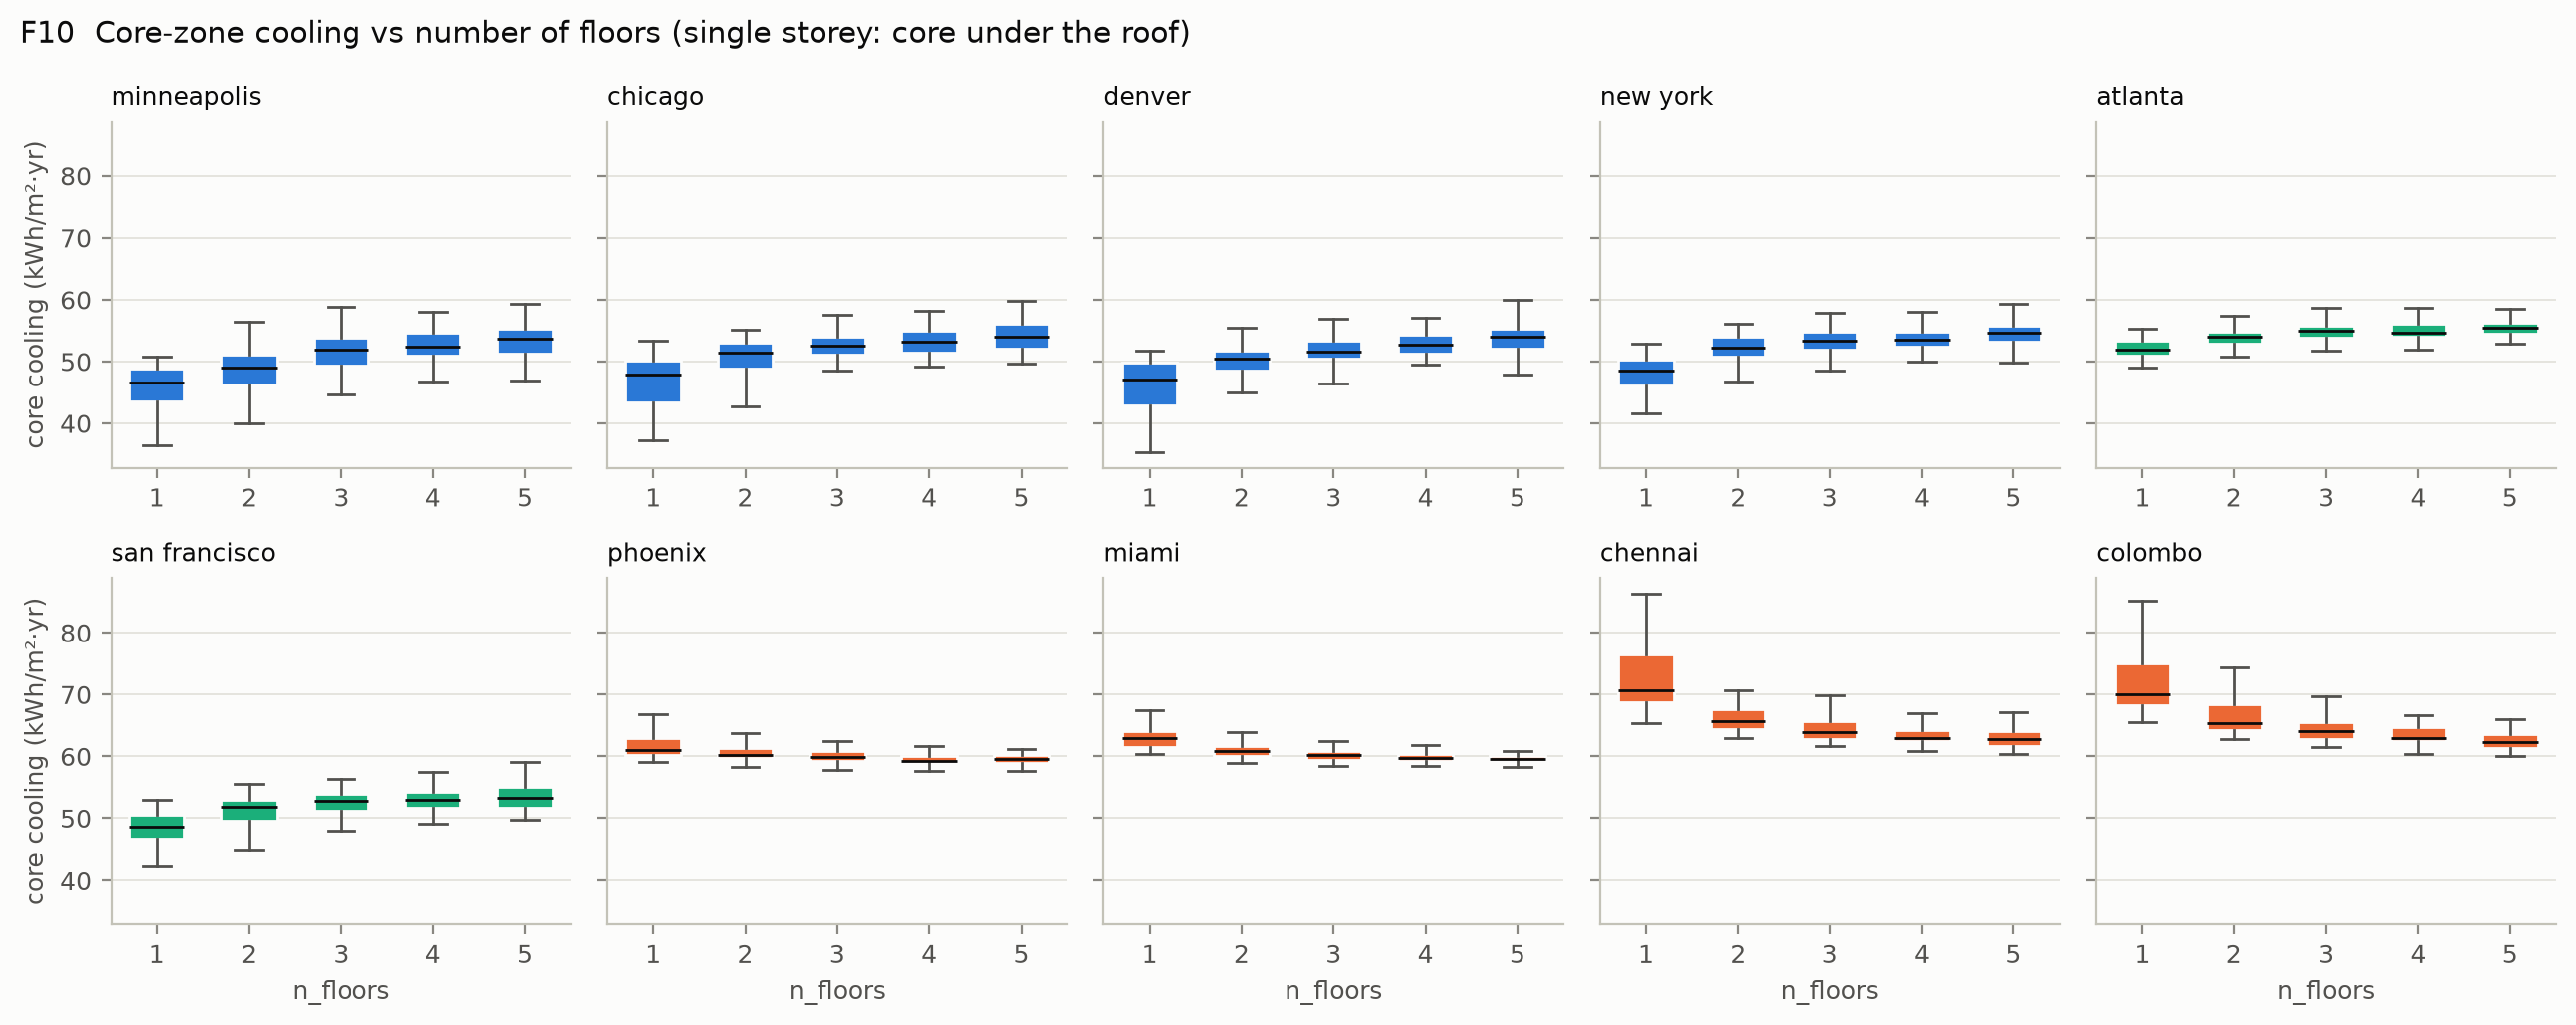

In [13]:
fig("F10_core_nfloors", 1200)

## E. Signal: can the design inputs be learned? (gate R1–R3)

In [14]:
s = pd.DataFrame(M["signal_grouped"])[["target", "r2", "climate_only_r2", "design_skill", "skill_climates", "within_r2_mean", "cv_rmse"]]
s

,target,r2,climate_only_r2,design_skill,skill_climates,within_r2_mean,cv_rmse
0,heating_demand_kwh_m2,0.891,0.631,0.704,7,0.687,0.426
1,cooling_demand_kwh_m2,0.886,0.545,0.749,10,0.753,0.096
2,eui_kwh_m2,0.977,0.930,0.680,10,0.661,0.056
3,peak_heating_w_m2,0.930,0.705,0.764,7,0.772,0.224
4,peak_cooling_w_m2,0.776,0.122,0.745,10,0.754,0.105
5,zone_cooling_core_kwh_m2,0.965,0.733,0.868,10,0.849,0.023
6,zone_cooling_south_kwh_m2,0.881,0.298,0.830,10,0.835,0.216
7,zone_cooling_east_kwh_m2,0.888,0.244,0.852,10,0.857,0.209
8,zone_cooling_north_kwh_m2,0.886,0.345,0.826,10,0.831,0.221
9,zone_cooling_west_kwh_m2,0.876,0.469,0.766,10,0.758,0.232


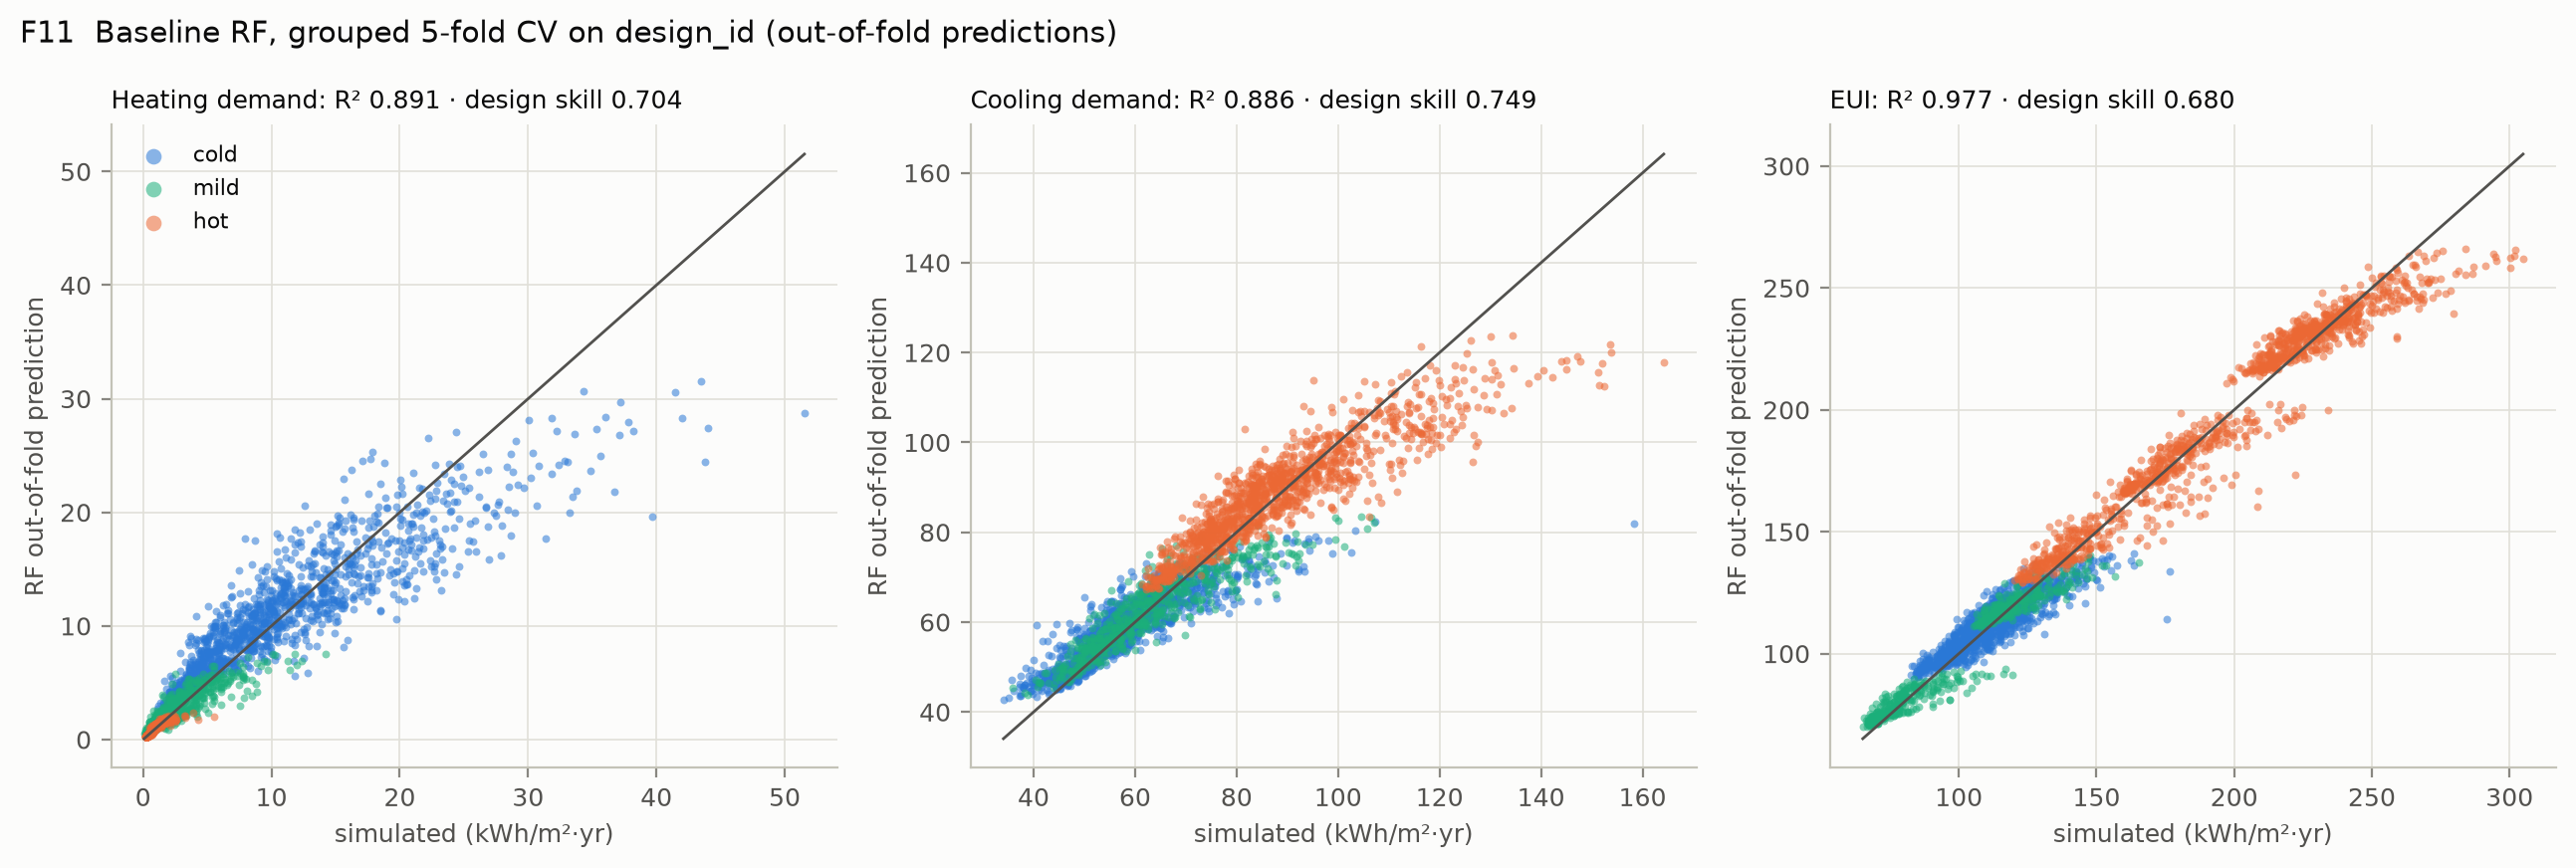

In [15]:
fig("F11_rf_parity", 1200)

In [16]:
print("Random 80/20 split vs grouped CV (anchor leakage gap)"); pd.DataFrame(M["leakage_gap"])

Random 80/20 split vs grouped CV (anchor leakage gap)


,target,r2_grouped,design_skill_grouped,r2_random,design_skill_random,r2_gap,skill_gap
0,heating_demand_kwh_m2,0.891,0.704,0.888,0.703,-0.003,-0.001
1,cooling_demand_kwh_m2,0.886,0.749,0.917,0.820,0.032,0.071
2,eui_kwh_m2,0.977,0.680,0.980,0.708,0.003,0.028
3,peak_heating_w_m2,0.930,0.764,0.948,0.823,0.018,0.058
4,peak_cooling_w_m2,0.776,0.745,0.823,0.796,0.047,0.051
5,zone_cooling_core_kwh_m2,0.965,0.868,0.974,0.896,0.010,0.028
6,zone_cooling_south_kwh_m2,0.881,0.830,0.917,0.885,0.036,0.055
7,zone_cooling_east_kwh_m2,0.888,0.852,0.920,0.900,0.031,0.048
8,zone_cooling_north_kwh_m2,0.886,0.826,0.914,0.865,0.029,0.039
9,zone_cooling_west_kwh_m2,0.876,0.766,0.901,0.824,0.025,0.057


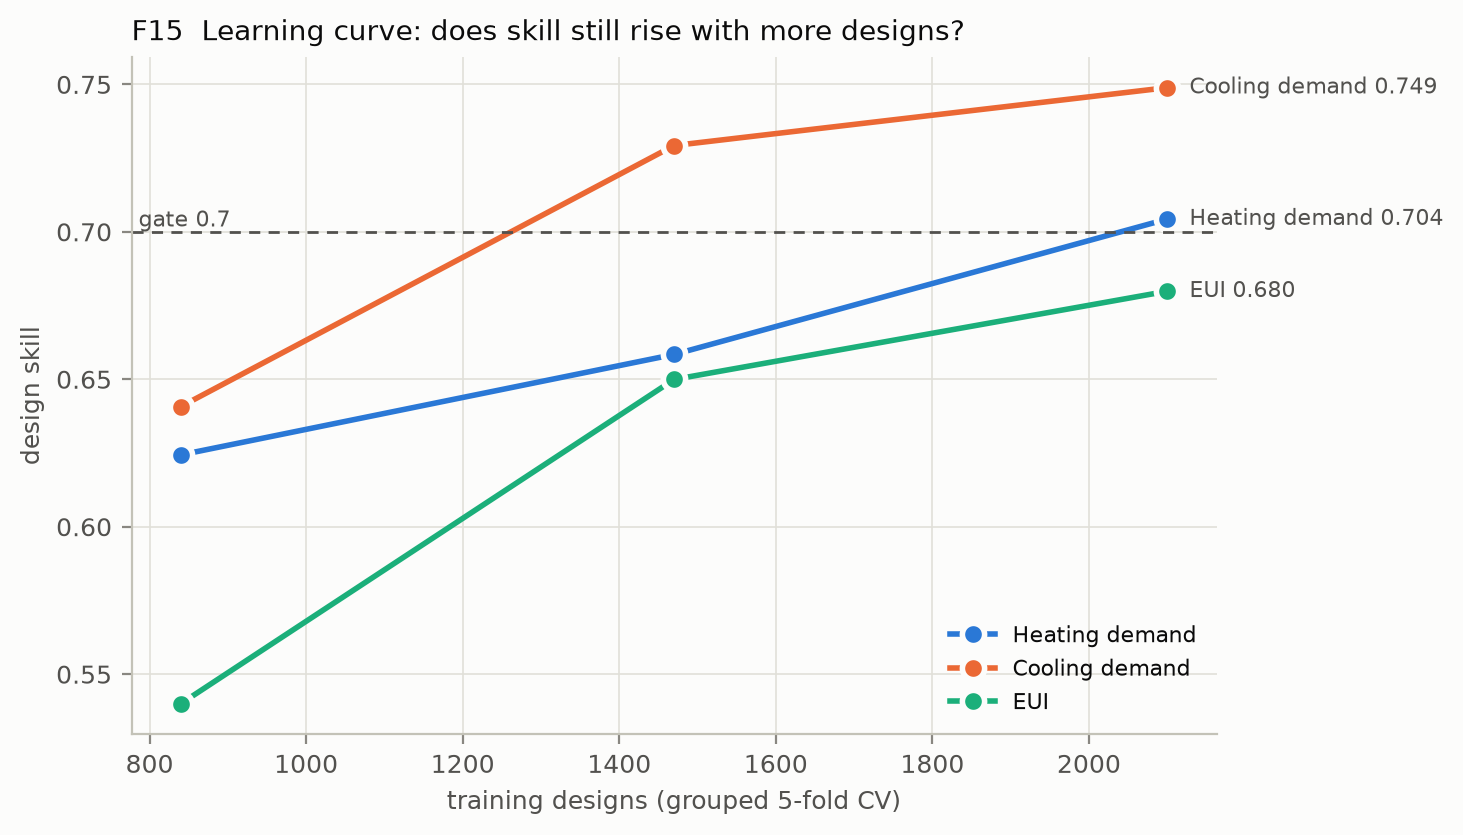

,fraction,n_designs,n_rows,target,design_skill,r2
0,0.4,840,1236,heating_demand_kwh_m2,0.624,0.862
1,0.4,840,1236,cooling_demand_kwh_m2,0.641,0.841
2,0.4,840,1236,eui_kwh_m2,0.540,0.968
3,0.7,1470,2145,heating_demand_kwh_m2,0.658,0.876
4,0.7,1470,2145,cooling_demand_kwh_m2,0.729,0.875
5,0.7,1470,2145,eui_kwh_m2,0.650,0.975
6,1.0,2100,3000,heating_demand_kwh_m2,0.704,0.891
7,1.0,2100,3000,cooling_demand_kwh_m2,0.749,0.886
8,1.0,2100,3000,eui_kwh_m2,0.680,0.977


In [17]:
fig("F15_learning_curve", 750)
pd.DataFrame(M["learning_curve"])

**Observation (gate).** Official run: 300 trees, grouped 5-fold CV on `design_id`.

| | Heating | Cooling | EUI |
|---|---|---|---|
| Pooled R² (R1 ≥ 0.85) | 0.891 ✅ | 0.886 ✅ | 0.977 ✅ |
| Climate-only R² | 0.631 | 0.545 | 0.930 |
| Design skill (R2 ≥ 0.70) | **0.704** ✅ | 0.749 ✅ | **0.680** ❌ |

Pooled R² looks excellent, but much of it comes from climate alone. Within a climate the untuned RF explains about 70–75 % of the
design-driven variance. EUI is the hardest target: it adds heating and cooling, which respond to SHGC in opposite directions, so its
within-climate R² is lowest in the cold climates (Denver 0.58, Minneapolis 0.60, New York 0.60). Peak cooling is the only secondary
target below 0.85 pooled R² (0.776, WARN), because it is 80 % design-driven and depends on a single worst hour.

Every data check passes and design skill still rises with more training designs (EUI 0.54 → 0.65 → 0.68 at 40/70/100 %).
EnergyPlus is deterministic, so the shortfall is the baseline model's capacity, not noise. Under the pre-registered Option C rule
(plan §5.1) the decision is **PROCEED (documented exception)**: Phase 3 must exceed 0.70 design skill on EUI.

A random 80/20 split would have overstated cooling skill by 0.07 and pooled R² by up to 0.05 (peak cooling), which confirms the
need for grouped CV (E2). Heating shows no gap.

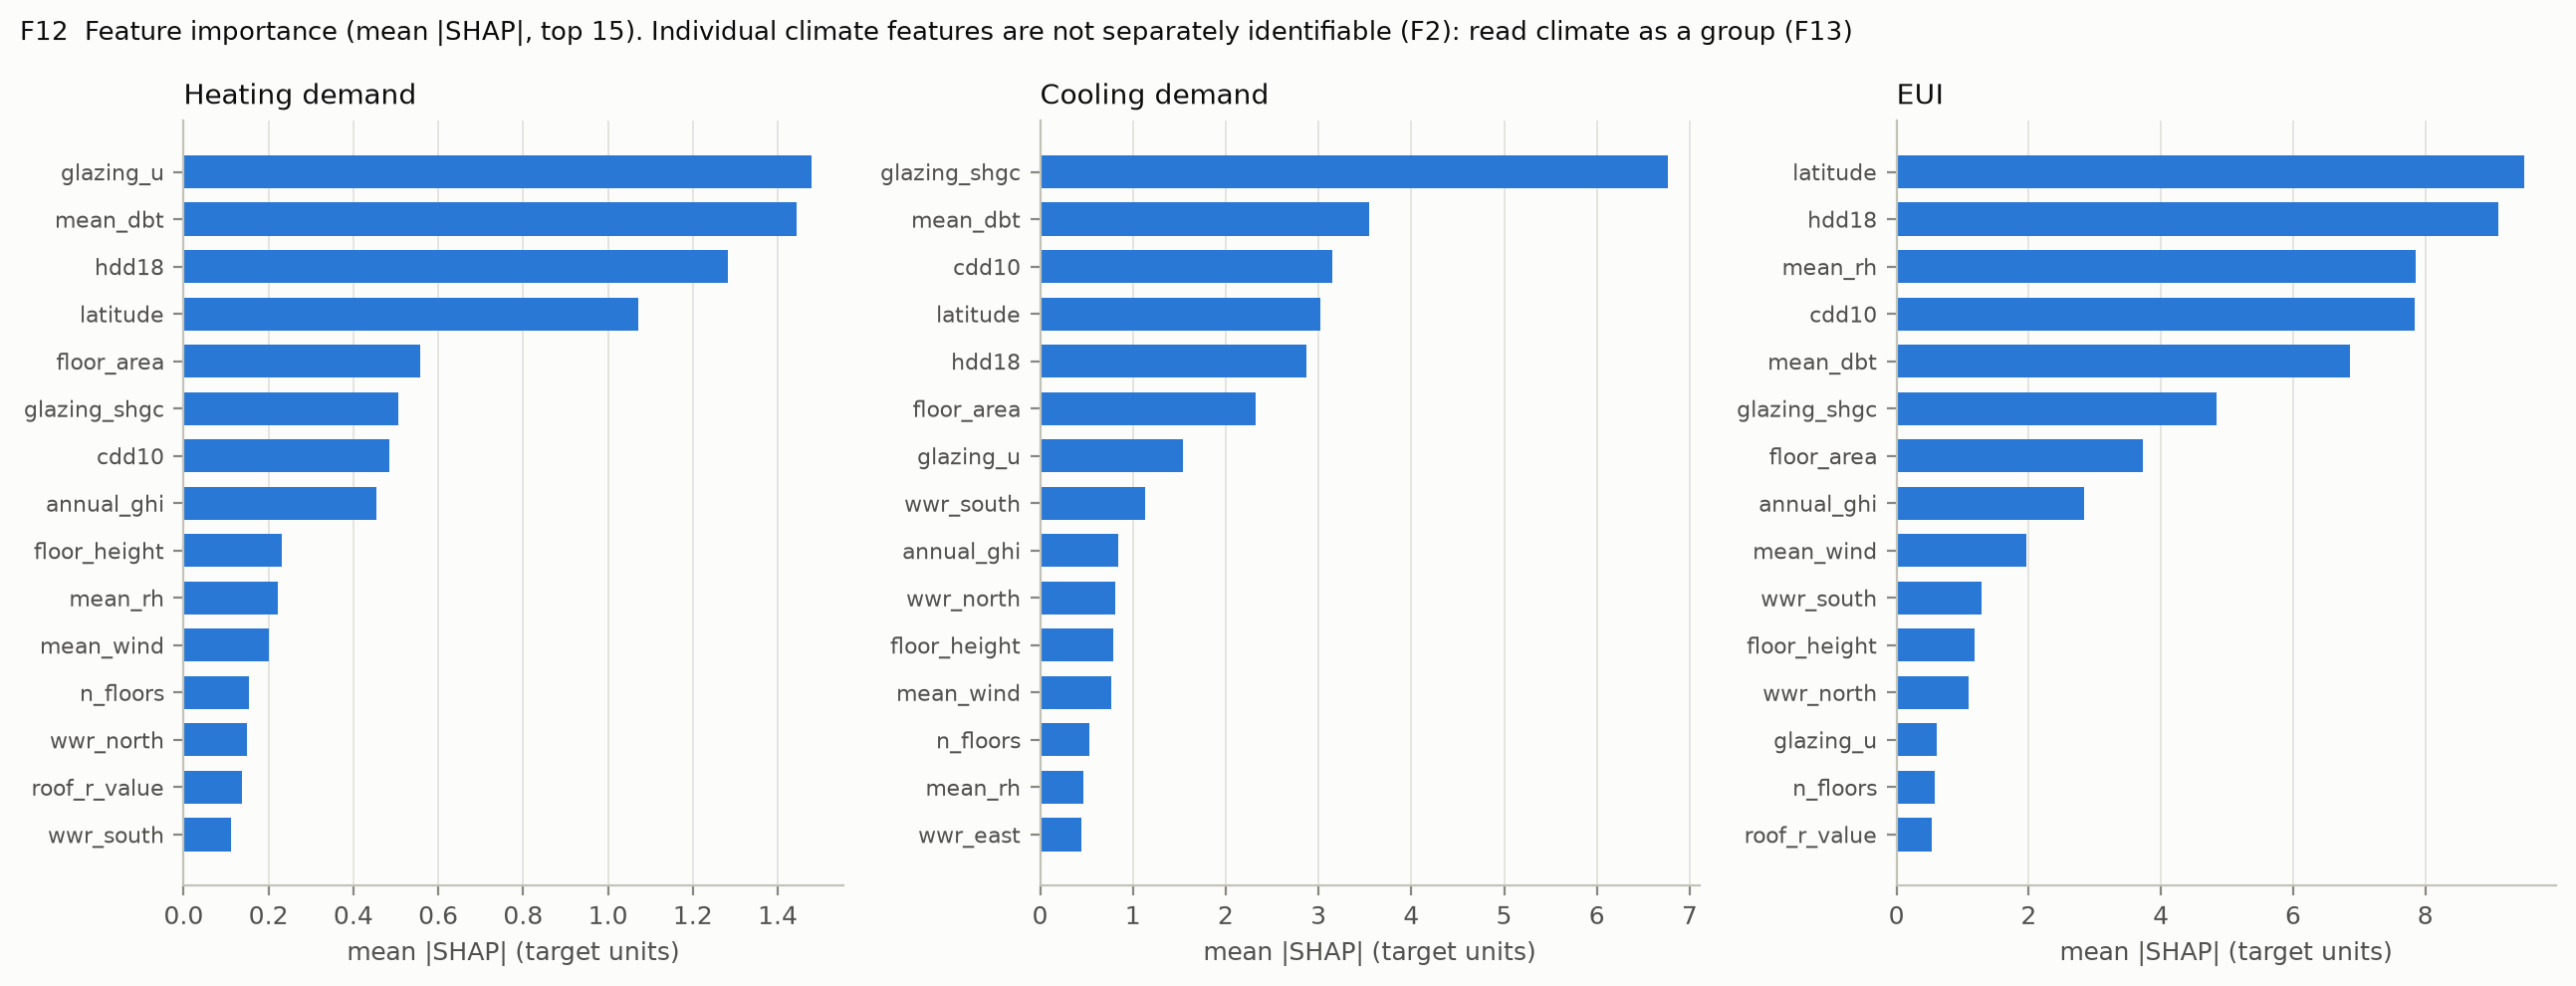

In [18]:
fig("F12_shap_features", 1200)

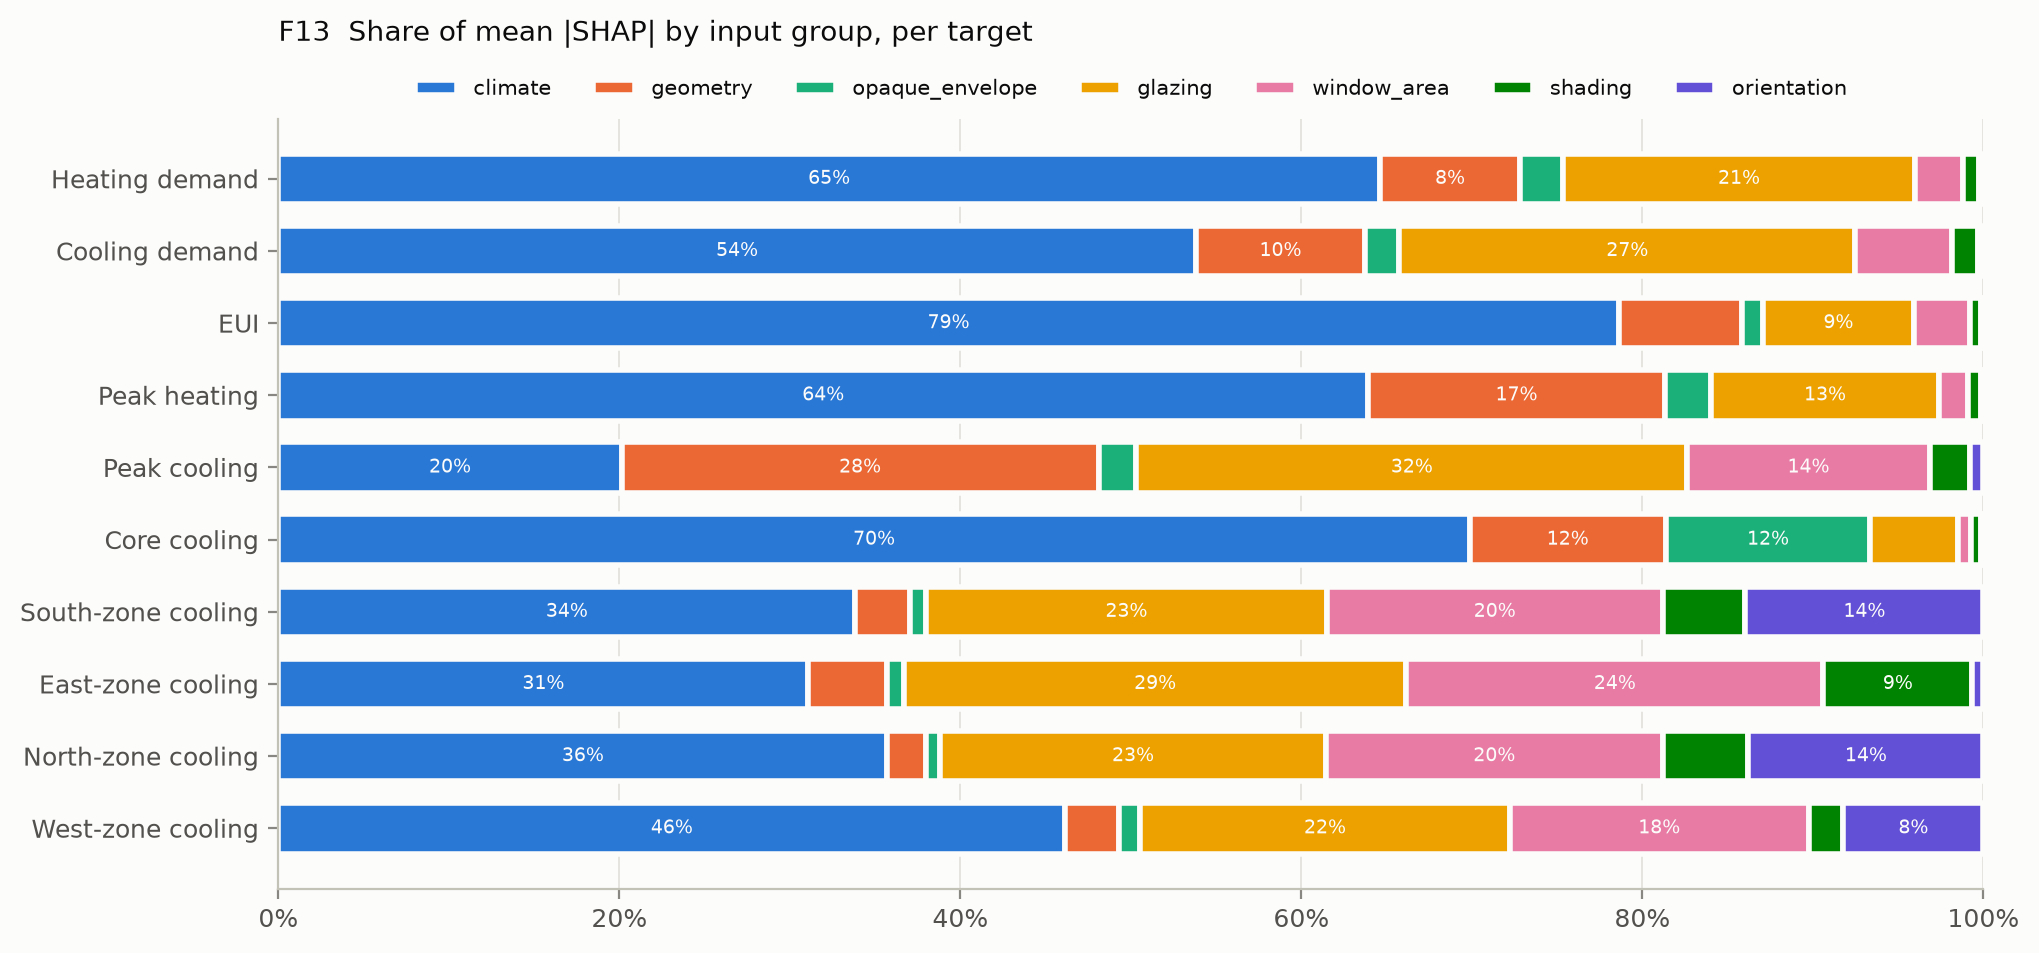

,climate,geometry,opaque_envelope,glazing,window_area,shading,orientation
heating_demand_kwh_m2,0.646,0.082,0.025,0.207,0.028,0.009,0.003
cooling_demand_kwh_m2,0.538,0.099,0.020,0.267,0.056,0.016,0.003
eui_kwh_m2,0.786,0.073,0.012,0.088,0.033,0.007,0.001
peak_heating_w_m2,0.639,0.174,0.027,0.134,0.017,0.008,0.002
peak_cooling_w_m2,0.201,0.280,0.022,0.323,0.142,0.024,0.008
zone_cooling_core_kwh_m2,0.699,0.115,0.120,0.052,0.008,0.006,0.001
zone_cooling_south_kwh_m2,0.338,0.032,0.010,0.235,0.197,0.048,0.140
zone_cooling_east_kwh_m2,0.311,0.046,0.010,0.295,0.245,0.087,0.006
zone_cooling_north_kwh_m2,0.357,0.022,0.009,0.226,0.198,0.050,0.138
zone_cooling_west_kwh_m2,0.461,0.031,0.013,0.217,0.176,0.020,0.082


In [19]:
fig("F13_shap_groups", 1100)
pd.DataFrame(M["shap_group_share"]).T

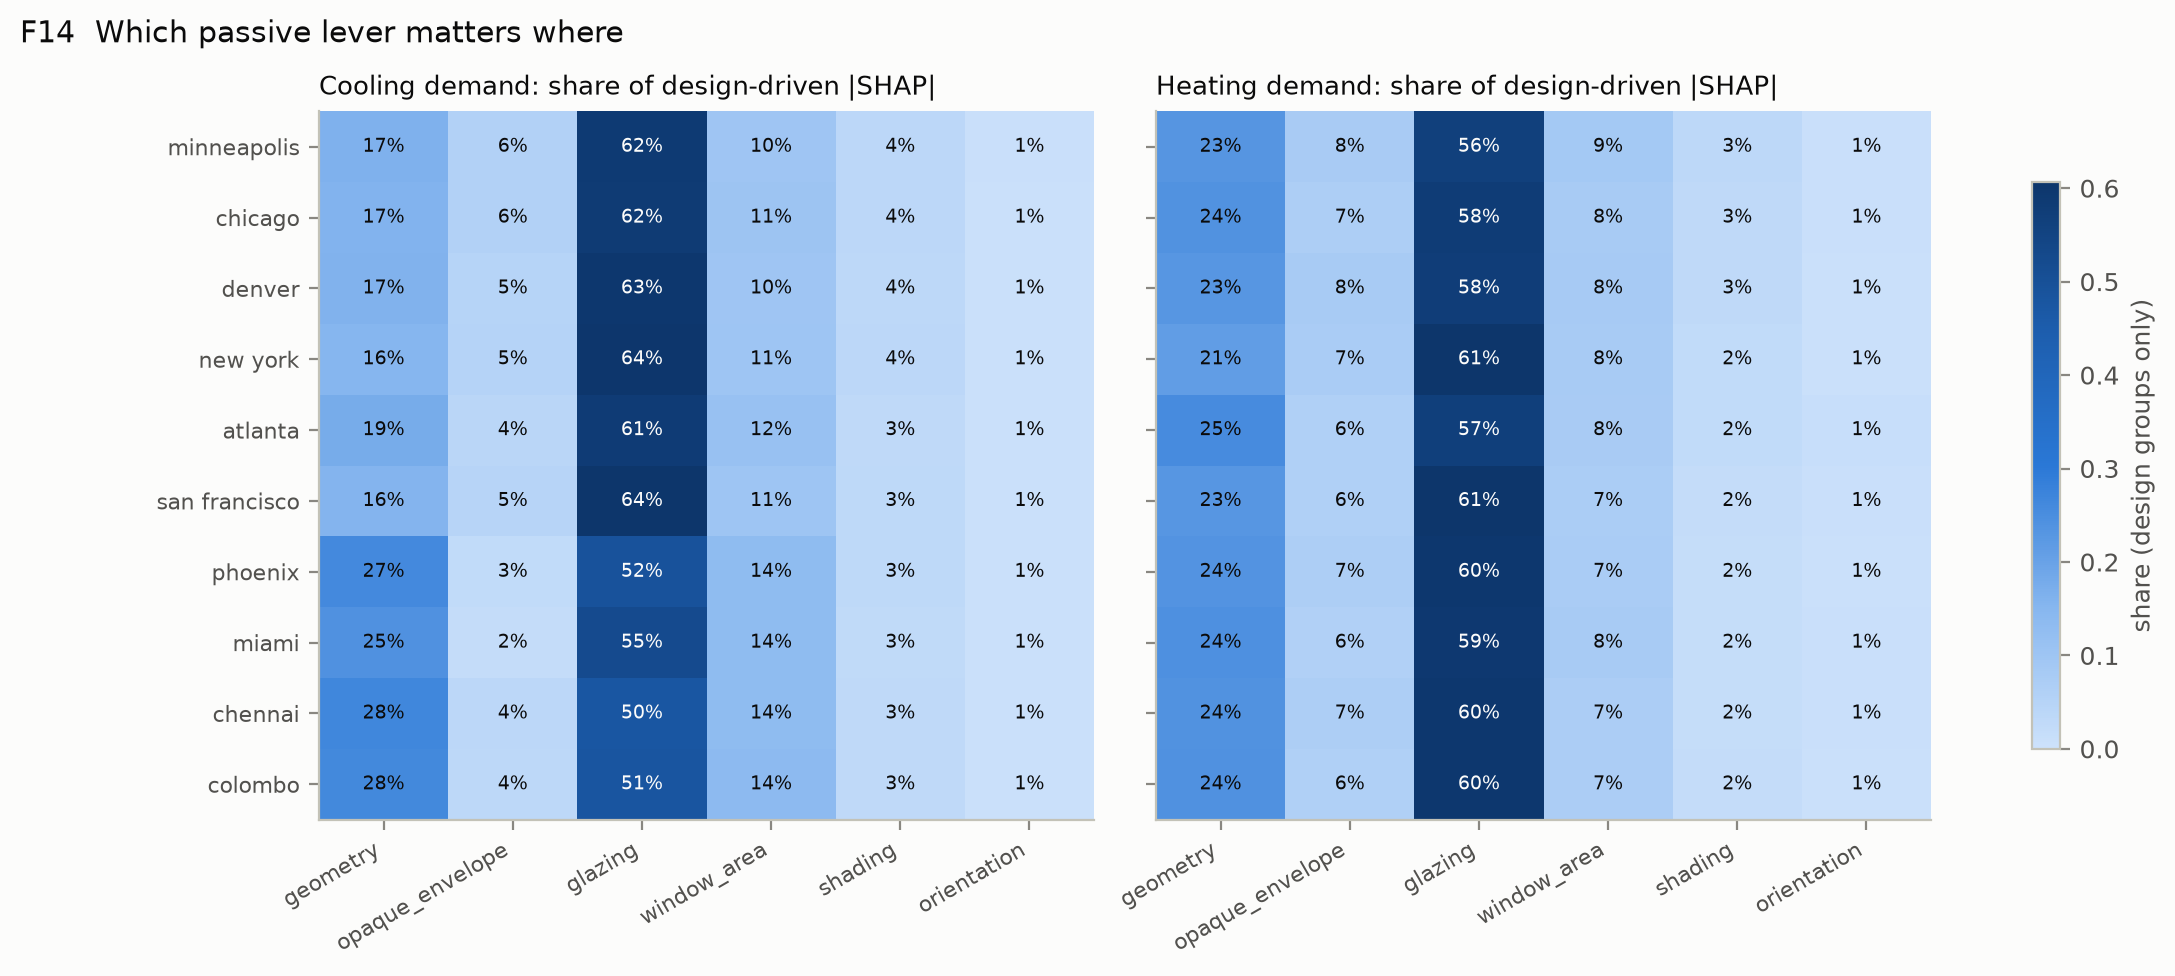

In [20]:
fig("F14_shap_by_climate", 1150)

**Observation.** Climate dominates EUI (79 % of mean |SHAP|), heating (65 %) and cooling (54 %), while peak cooling (climate 20 %;
glazing 32 %, geometry 28 %, window area 14 %) and the perimeter zones (climate 31–46 %) are mostly design-driven. Glazing (U, SHGC) is
the largest design lever for every primary target, with `glazing_u` the top individual feature for heating and `glazing_shgc` for
cooling. Orientation matters only for the zones whose façades swing between north and south (≈ 14 % for the north and south zones,
8 % west, < 1 % east). Opaque envelope and shading are small at this design-space scale. Individual climate features are not separately
identifiable (F2), so climate is read as a group. The heating panel of F14 includes the three tropical climates, where heating is ≈ 0;
read those rows as relative shares of a negligible load.

## Residual review (R4)

In [21]:
r = pd.read_csv(OUT / "top_residuals.csv")
r.groupby("target", sort=False).head(5)

,run_id,climate_key,target,fold,y,yhat,scheme,abs_err,outlier_targets,err_warnings,accepted_exception
0,main_B0977_denver,denver,cooling_demand_kwh_m2,4,158.381,81.881,grouped,76.500,cooling_demand_kwh_m2;eui_kwh_m2;peak_cooling_w_m2;zone_cooling_south_kwh_m2,3,NaN
1,main_B0977_denver,denver,eui_kwh_m2,4,175.619,114.175,grouped,61.444,cooling_demand_kwh_m2;eui_kwh_m2;peak_cooling_w_m2;zone_cooling_south_kwh_m2,3,NaN
2,main_B1690_phoenix,phoenix,eui_kwh_m2,0,222.086,173.308,grouped,48.778,cooling_demand_kwh_m2;eui_kwh_m2;peak_cooling_w_m2;zone_cooling_south_kwh_m2,0,NaN
3,main_B1783_phoenix,phoenix,eui_kwh_m2,1,208.414,160.386,grouped,48.028,NaN,0,NaN
4,main_B1690_phoenix,phoenix,cooling_demand_kwh_m2,0,164.173,117.751,grouped,46.422,cooling_demand_kwh_m2;eui_kwh_m2;peak_cooling_w_m2;zone_cooling_south_kwh_m2,0,NaN
5,main_B0761_colombo,colombo,eui_kwh_m2,4,304.914,261.966,grouped,42.948,eui_kwh_m2,1,NaN
6,main_B0460_chicago,chicago,eui_kwh_m2,3,176.431,133.934,grouped,42.497,eui_kwh_m2;peak_heating_w_m2;peak_cooling_w_m2,1,NaN
10,main_B1783_phoenix,phoenix,cooling_demand_kwh_m2,1,152.397,112.562,grouped,39.835,NaN,0,NaN
11,main_B1644_phoenix,phoenix,cooling_demand_kwh_m2,4,151.411,112.728,grouped,38.683,NaN,0,NaN
15,main_B0761_colombo,colombo,cooling_demand_kwh_m2,4,151.279,115.501,grouped,35.778,eui_kwh_m2,1,NaN


**Observation (R4).** All 60 of the largest errors (20 per primary target) are **under-predictions**, i.e. the RF regresses
extreme designs towards the mean. They share one physical profile: small, narrow footprints (median floor area ≈ 2,000 m² vs 5,750
for the dataset) with high WWR (≈ 0.75) and, for cooling/EUI, high SHGC (median 0.72), mostly in Chennai and Phoenix; or, for heating,
high glazing U (median 5.1) with low SHGC (0.19) in Minneapolis and Chicago. Small, narrow plans have the most façade, and therefore
the most glass, per m² of floor.

The largest error, `main_B0977_denver` (cooling 158 vs predicted 82 kWh/m²), is physically plausible: it has the highest solar aperture
in Denver (glazed area per floor area × SHGC = 0.179, second-highest of all 3,000 runs), a clean EnergyPlus run, and it was already
flagged as a 4σ outlier in 2.7. Across all runs the cooling residual correlates with solar aperture (ρ = 0.47). The model misses
exactly the multiplicative driver that trees approximate poorly, which motivates the first Phase 3 engineered feature. No residual
points to a data error.

## Decisions carried into Phase 3

- **CV:** GroupKFold(5) on `design_id`; report pooled R², **design skill**, MAE/RMSE/CV(RMSE); heating skill over the 7 heating climates only.
- **Baseline to beat (untuned RF, 300 trees):** design skill heating 0.704, cooling 0.749, **EUI 0.680 (must exceed 0.70)**; pooled R² 0.891 / 0.886 / 0.977.
- **Engineered features to test first:** solar aperture (Σ façade glazed area × SHGC / floor area) and glazing area per floor area (residual ρ = 0.47);
  true façade azimuth (sin/cos); roof-exposure indicator for `n_floors = 1`.
- **Targets:** test `log1p(heating)`; treat EUI as a sum of competing terms (consider predicting system heating/cooling separately and summing).
- **Climate features:** read importance as a group; consider dropping near-duplicates (CDD10 vs mean DBT, ρ 0.98). London is an extrapolation test.
- Install `xgboost` and `lightgbm` in the Mac venv at the start of Phase 3.